Dataset link: https://www.kaggle.com/datasets/parthpatil256/it-support-ticket-data

In [ ]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')
file_path = '/content/drive/MyDrive/IT Support Ticket Data.csv'

df = pd.read_csv(file_path, index_col=0)

display(df.head())

Mounted at /content/drive


,Body,Department,Priority,Tags
0,"Dear Customer Support Team,I am writing to rep...",Technical Support,high,"['Account', 'Disruption', 'Outage', 'IT', 'Tec..."
1,"Dear Customer Support Team,I hope this message...",Returns and Exchanges,medium,"['Product', 'Feature', 'Tech Support']"
2,"Dear Customer Support Team,I hope this message...",Billing and Payments,low,"['Billing', 'Payment', 'Account', 'Documentati..."
3,"Dear Support Team,I hope this message reaches ...",Sales and Pre-Sales,medium,"['Product', 'Feature', 'Feedback', 'Tech Suppo..."
4,"Dear Customer Support,I hope this message reac...",Technical Support,high,"['Feature', 'Product', 'Documentation', 'Feedb..."


In [ ]:
print('--- DataFrame Info ---')
df.info()

print('\n--- DataFrame Shape ---')
print(f'Rows: {df.shape[0]}, Columns: {df.shape[1]}')

print('\n--- Descriptive Statistics ---')
display(df.describe(include='all'))

--- DataFrame Info ---
<class 'pandas.core.frame.DataFrame'>
Index: 29651 entries, 0 to 29650
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Body        29650 non-null  object
 1   Department  29651 non-null  object
 2   Priority    29651 non-null  object
 3   Tags        29651 non-null  object
dtypes: object(4)
memory usage: 1.1+ MB

--- DataFrame Shape ---
Rows: 29651, Columns: 4

--- Descriptive Statistics ---


,Body,Department,Priority,Tags
count,29650,29651,29651,29651
unique,25055,10,3,12946
top,The data analytics tool experiences sluggish p...,Technical Support,medium,"['Bug', 'Performance', 'IT', 'Tech Support']"
freq,2,8617,12126,878


In [ ]:
print('--- Missing Values Count ---')
missing_values = df.isnull().sum()
print(missing_values)

print('\n--- Duplicated Rows Count ---')
duplicate_count = df.duplicated().sum()
print(f'Total duplicate rows: {duplicate_count}')

--- Missing Values Count ---
Body          1
Department    0
Priority      0
Tags          0
dtype: int64

--- Duplicated Rows Count ---
Total duplicate rows: 4428


In [ ]:
df = df.drop_duplicates().reset_index(drop=True)
print(f'Shape after removing duplicates: {df.shape}')
print(f'Rows removed: {29651 - len(df)}')

Shape after removing duplicates: (25223, 4)
Rows removed: 4428


In [ ]:
df = df.dropna(subset=['Body']).reset_index(drop=True)
print(f'Shape after removing missing values: {df.shape}')
print(f'Rows removed: 1')

Shape after removing missing values: (25222, 4)
Rows removed: 1


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

TEXT_COL  = "Body"
LABEL_COL = "Department"

df_raw = df.copy()

X_text = df_raw[TEXT_COL]
y      = df_raw[LABEL_COL]

X_train_text, X_temp_text, y_train, y_temp = train_test_split(
    X_text, y, test_size=0.2, random_state=42, stratify=y)
X_val_text, X_test_text, y_val, y_test = train_test_split(
    X_temp_text, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

n_total = len(X_text)
print(f"Total rows (with dup): {n_total}")
print(f"Train: {len(X_train_text)} ({len(X_train_text)/n_total*100:.1f}%)  "
      f"Val: {len(X_val_text)} ({len(X_val_text)/n_total*100:.1f}%)  "
      f"Test: {len(X_test_text)} ({len(X_test_text)/n_total*100:.1f}%)")


train_bodies = set(X_train_text.astype(str))

test_leaked = X_test_text.astype(str).isin(train_bodies)
val_leaked  = X_val_text.astype(str).isin(train_bodies)

n_test_leak = int(test_leaked.sum())
n_val_leak  = int(val_leaked.sum())

print("\n--- Input-level leakage (Body appears in train) ---")
print(f"TEST : {n_test_leak}/{len(X_test_text)} = {n_test_leak/len(X_test_text)*100:.2f}%")
print(f"VAL  : {n_val_leak}/{len(X_val_text)}  = {n_val_leak/len(X_val_text)*100:.2f}%")


train_pairs = set(zip(X_train_text.astype(str), y_train.astype(str)))
test_pair_leak = sum(
    (b, l) in train_pairs
    for b, l in zip(X_test_text.astype(str), y_test.astype(str))
)
print("\n--- (Body, Department) leakage in TEST ---")
print(f"TEST : {test_pair_leak}/{len(X_test_text)} = {test_pair_leak/len(X_test_text)*100:.2f}%")


dup_full = df_raw.duplicated().sum()
dup_body = df_raw[TEXT_COL].duplicated().sum()
print("\n--- Duplicate counts in full corpus ---")
print(f"Full-row duplicates : {dup_full}")
print(f"Body duplicates     : {dup_body}")

Total rows (with dup): 29650
Train: 23720 (80.0%)  Val: 2965 (10.0%)  Test: 2965 (10.0%)

--- Input-level leakage (Body appears in train) ---
TEST : 741/2965 = 24.99%
VAL  : 748/2965  = 25.23%

--- (Body, Department) leakage in TEST ---
TEST : 738/2965 = 24.89%

--- Duplicate counts in full corpus ---
Full-row duplicates : 4428
Body duplicates     : 4595


--- Department Distribution ---


,Count,Percentage (%)
Department,,
Technical Support,7345,29.121402
Product Support,4670,18.515582
Customer Service,3789,15.022599
IT Support,3009,11.930061
Billing and Payments,2563,10.161764
Returns and Exchanges,1243,4.928237
Service Outages and Maintenance,1000,3.964793
Sales and Pre-Sales,768,3.044961
Human Resources,477,1.891206



--- Priority Distribution ---


,Count,Percentage (%)
Priority,,
medium,10339,40.991991
high,9790,38.815320
low,5093,20.192689


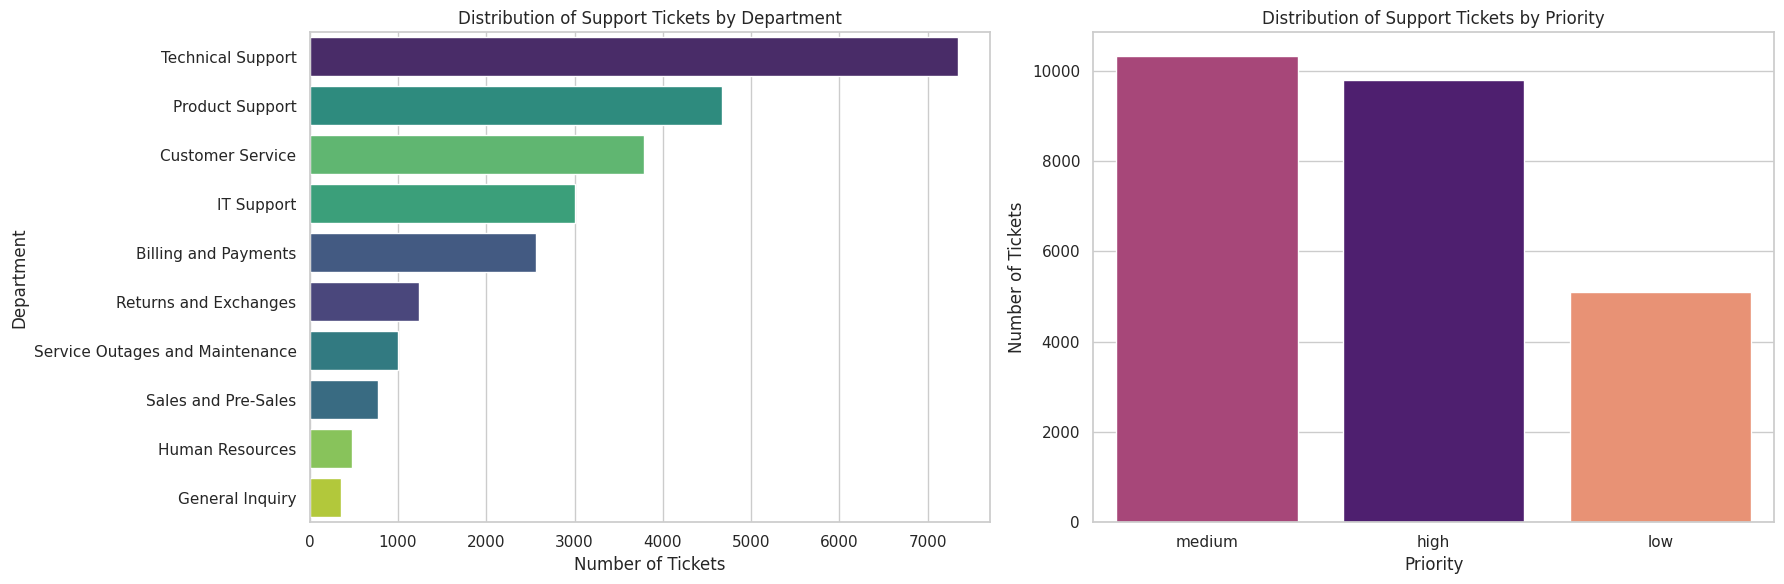


Total Unique Tags: 1650
Average tags per ticket: 5.03


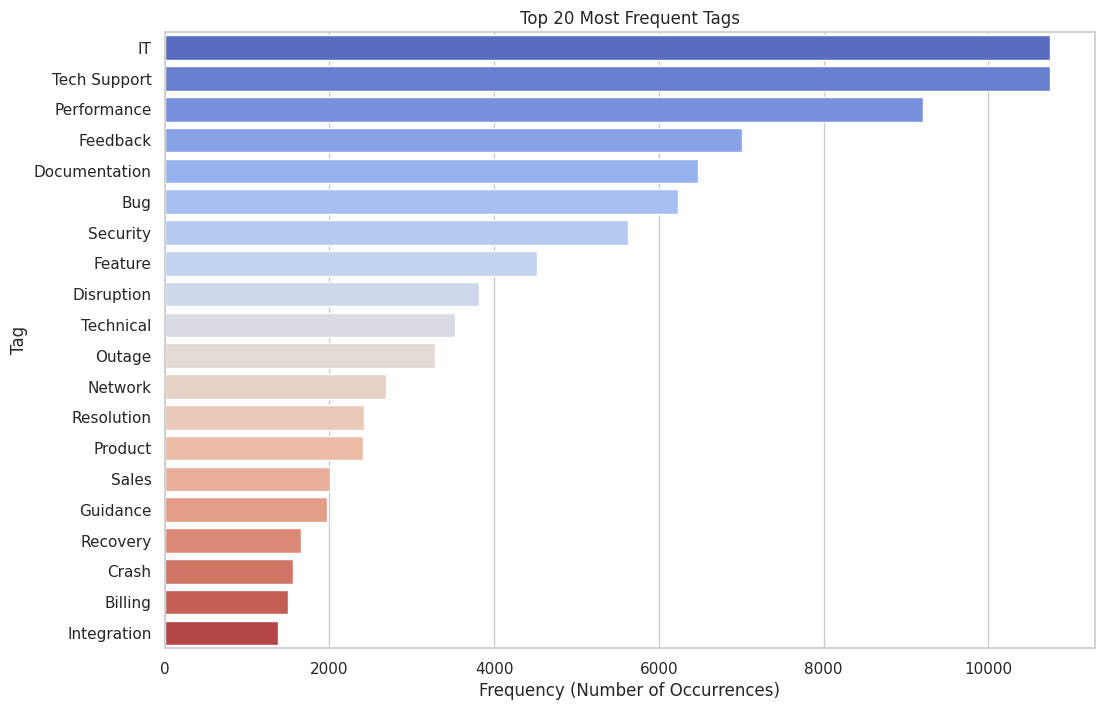

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import ast
from collections import Counter
import pandas as pd

# 1. Calculate counts and percentages for Department and Priority
dept_counts = df['Department'].value_counts()
dept_percent = df['Department'].value_counts(normalize=True) * 100
prio_counts = df['Priority'].value_counts()
prio_percent = df['Priority'].value_counts(normalize=True) * 100

print('--- Department Distribution ---')
display(pd.DataFrame({'Count': dept_counts, 'Percentage (%)': dept_percent}))

print('\n--- Priority Distribution ---')
display(pd.DataFrame({'Count': prio_counts, 'Percentage (%)': prio_percent}))

# 2. Visualization of distributions (Department and Priority)
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.countplot(data=df, y='Department', ax=axes[0], hue='Department', palette='viridis', order=dept_counts.index, legend=False)
axes[0].set_title('Distribution of Support Tickets by Department')
axes[0].set_xlabel('Number of Tickets')

sns.countplot(data=df, x='Priority', ax=axes[1], hue='Priority', palette='magma', order=prio_counts.index, legend=False)
axes[1].set_title('Distribution of Support Tickets by Priority')
axes[1].set_ylabel('Number of Tickets')

plt.tight_layout()
plt.show()

# 3. Parse 'Tags' column and Tag statistics
def parse_tags(tag_str):
    try:
        return ast.literal_eval(tag_str)
    except:
        return []

df['Tags_cleaned'] = df['Tags'].apply(parse_tags)
num_tags_per_ticket = df['Tags_cleaned'].apply(len)

flattened_tags = [tag for sublist in df['Tags_cleaned'] for tag in sublist]
tag_freq = Counter(flattened_tags)
unique_tags_count = len(tag_freq)
common_tags = tag_freq.most_common(20)

print(f'\nTotal Unique Tags: {unique_tags_count}')
print(f'Average tags per ticket: {num_tags_per_ticket.mean():.2f}')

# 4. Visualization of Top 20 Tags
tag_freq_df = pd.DataFrame(common_tags, columns=['Tag', 'Frequency'])

plt.figure(figsize=(12, 8))
sns.barplot(data=tag_freq_df, x='Frequency', y='Tag', hue='Tag', palette='coolwarm', legend=False)
plt.title('Top 20 Most Frequent Tags')
plt.xlabel('Frequency (Number of Occurrences)')
plt.ylabel('Tag')
plt.show()

--- Professional Department Distribution Analysis ---


,Count,Percentage (%)
Department,,
Technical Support,7345,29.12
Product Support,4670,18.52
Customer Service,3789,15.02
IT Support,3009,11.93
Billing and Payments,2563,10.16
Returns and Exchanges,1243,4.93
Service Outages and Maintenance,1000,3.96
Sales and Pre-Sales,768,3.04
Human Resources,477,1.89


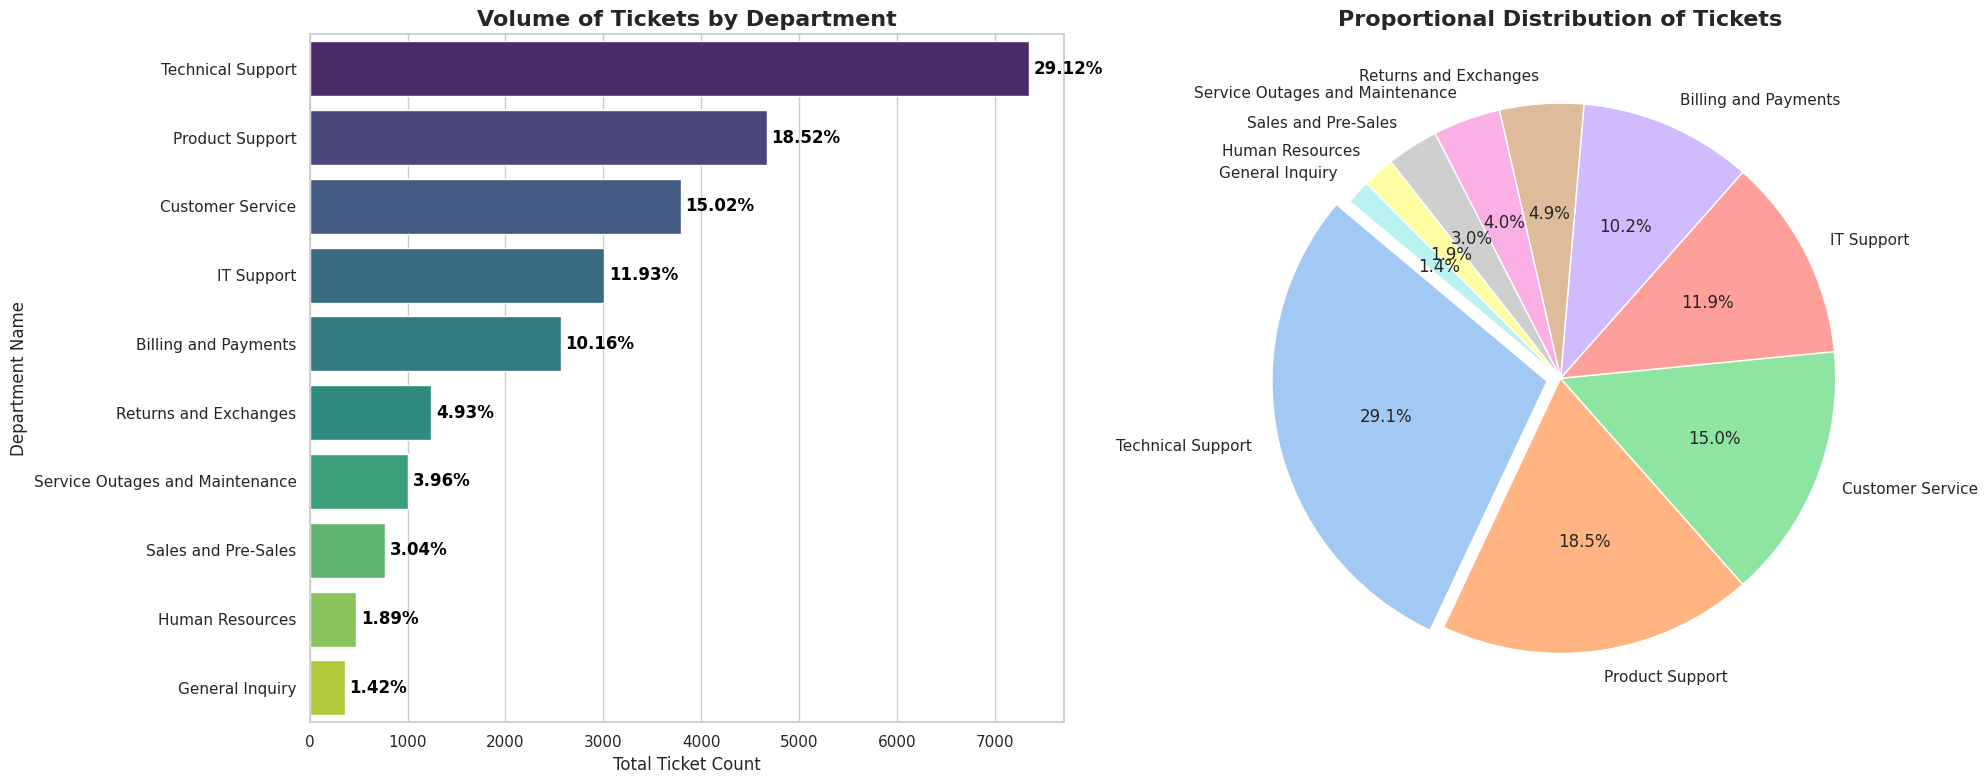


KEY EDA INSIGHTS
• Market Leader: Technical Support dominates with 29.12% of total volume.
• Tail End: General Inquiry represents the smallest segment at 1.42%.
• Skewness: The top 3 departments handle over 60% of the total workload.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Statistical Breakdown
dept_counts = df['Department'].value_counts()
dept_percent = df['Department'].value_counts(normalize=True) * 100
dept_stats = pd.DataFrame({'Count': dept_counts, 'Percentage (%)': dept_percent.round(2)})

print('--- Professional Department Distribution Analysis ---')
display(dept_stats)

# 2. Enhanced Multi-Graph Visualization
sns.set_theme(style='whitegrid', palette='muted')
fig, ax = plt.subplots(1, 2, figsize=(20, 8))

# A. Bar Chart with Annotations
sns.barplot(x=dept_stats['Count'], y=dept_stats.index, ax=ax[0], palette='viridis', hue=dept_stats.index, legend=False)
ax[0].set_title('Volume of Tickets by Department', fontsize=16, fontweight='bold')
ax[0].set_xlabel('Total Ticket Count', fontsize=12)
ax[0].set_ylabel('Department Name', fontsize=12)

# Add percentage labels to bars
for i, v in enumerate(dept_stats['Count']):
    ax[0].text(v + 50, i, f"{dept_stats['Percentage (%)'].iloc[i]}%", color='black', va='center', fontweight='bold')

# B. Pie Chart for Proportional Share
ax[1].pie(dept_stats['Count'], labels=dept_stats.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'), explode=[0.05 if i == 0 else 0 for i in range(len(dept_stats))])
ax[1].set_title('Proportional Distribution of Tickets', fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()

# 3. Insightful Summary
print('\n' + '='*50)
print('KEY EDA INSIGHTS')
print('='*50)
print(f'• Market Leader: {dept_stats.index[0]} dominates with {dept_stats["Percentage (%)"].iloc[0]}% of total volume.')
print(f'• Tail End: {dept_stats.index[-1]} represents the smallest segment at {dept_stats["Percentage (%)"].iloc[-1]}%.')
print(f'• Skewness: The top 3 departments handle over 60% of the total workload.')
print('='*50)

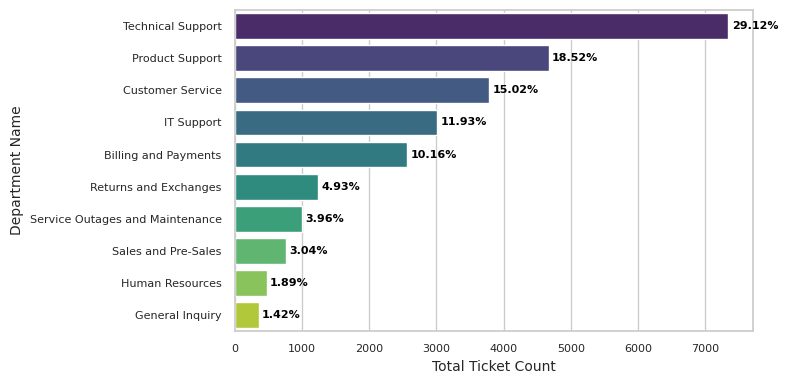

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# Department counts and percentages
dept_counts = df['Department'].value_counts()
dept_percent = df['Department'].value_counts(normalize=True) * 100
dept_stats = pd.DataFrame({
    'Count': dept_counts,
    'Percentage (%)': dept_percent.round(2)
})

# Shorter single bar chart
sns.set_theme(style='whitegrid', palette='muted')

fig, ax = plt.subplots(figsize=(8, 4.0))

sns.barplot(
    x=dept_stats['Count'],
    y=dept_stats.index,
    ax=ax,
    palette='viridis',
    hue=dept_stats.index,
    legend=False
)

# Percentage labels
for i, v in enumerate(dept_stats['Count']):
    ax.text(
        v + 50,
        i,
        f"{dept_stats['Percentage (%)'].iloc[i]}%",
        color='black',
        va='center',
        fontsize=8,
        fontweight='bold'
    )

# No title
ax.set_xlabel('Total Ticket Count', fontsize=10)
ax.set_ylabel('Department Name', fontsize=10)

ax.tick_params(axis='x', labelsize=8)
ax.tick_params(axis='y', labelsize=8)

plt.tight_layout()

# Save image
os.makedirs('figures', exist_ok=True)
output_path = 'figures/class_distribution.png'

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# Download image
files.download(output_path)

## Class Imbalance Analysis

Quantifying the imbalance ratio is critical for choosing the right modeling strategy.

In [ ]:
# === Class Imbalance Ratio ===
dept_counts = df['Department'].value_counts()
largest_class = dept_counts.iloc[0]
smallest_class = dept_counts.iloc[-1]

imbalance_ratio = largest_class / smallest_class

print(f"Largest class:  {dept_counts.index[0]} ({largest_class} samples)")
print(f"Smallest class: {dept_counts.index[-1]} ({smallest_class} samples)")
print(f"Imbalance Ratio: {imbalance_ratio:.1f}x")
print()
print("--- Imbalance Summary ---")
for dept, count in dept_counts.items():
    ratio_to_largest = largest_class / count
    print(f"  {dept:40s} {count:5d}  ({ratio_to_largest:.1f}x smaller than largest)")

print(f"\n→ The dataset has a {imbalance_ratio:.0f}:1 imbalance ratio.")
print("→ This means class_weight='balanced' or stratified sampling is essential.")

Largest class:  Technical Support (7345 samples)
Smallest class: General Inquiry (358 samples)
Imbalance Ratio: 20.5x

--- Imbalance Summary ---
  Technical Support                         7345  (1.0x smaller than largest)
  Product Support                           4670  (1.6x smaller than largest)
  Customer Service                          3789  (1.9x smaller than largest)
  IT Support                                3009  (2.4x smaller than largest)
  Billing and Payments                      2563  (2.9x smaller than largest)
  Returns and Exchanges                     1243  (5.9x smaller than largest)
  Service Outages and Maintenance           1000  (7.3x smaller than largest)
  Sales and Pre-Sales                        768  (9.6x smaller than largest)
  Human Resources                            477  (15.4x smaller than largest)
  General Inquiry                            358  (20.5x smaller than largest)

→ The dataset has a 21:1 imbalance ratio.
→ This means class_weight='bal

In [ ]:
df['wc'] = df['Body'].apply(lambda x: len(str(x).split()))
print(df['wc'].describe())
print(f"< 10 words: {(df['wc']<10).sum()} ({(df['wc']<10).sum()/len(df)*100:.1f}%)")
print(f"> 200 words: {(df['wc']>200).sum()} ({(df['wc']>200).sum()/len(df)*100:.1f}%)")

count    25222.000000
mean        58.641266
std         36.315661
min          1.000000
25%         31.000000
50%         56.000000
75%         80.000000
max        350.000000
Name: wc, dtype: float64
< 10 words: 1193 (4.7%)
> 200 words: 132 (0.5%)


In [ ]:
import re

# 1. Sample 10 random entries for manual inspection
sample_bodies = df['Body'].dropna().sample(10, random_state=42)
print('--- Sample Ticket Bodies ---')
for i, text in enumerate(sample_bodies, 1):
    print(f'Sample {i}:\n{text[:300]}...')
    print('-' * 40)

# 2. Define regex patterns
html_pattern = r'<[^>]+>'
url_pattern = r'http[s]?://(?:[a-zA-Z]|[0-9]|[$-_@.&+]|[!*\\(\\),]|(?:%[0-9a-fA-F][0-9a-fA-F]))+'

# 3. Apply patterns to count occurrences
# We fillna with empty string to avoid errors during regex search
body_series = df['Body'].fillna('')

has_html = body_series.str.contains(html_pattern, regex=True).sum()
has_url = body_series.str.contains(url_pattern, regex=True).sum()

print('\n--- Text Cleaning Requirements Analysis ---')
print(f'Total rows with HTML tags: {has_html}')
print(f'Total rows with URLs: {has_url}')

# 4. Check for common boilerplate examples
boilerplate_examples = [
    'Dear Customer Support Team',
    'Kind regards',
    'I hope this message finds you well',
    'Thank you for your assistance'
]

print('\n--- Boilerplate Detection Check ---')
for phrase in boilerplate_examples:
    count = body_series.str.contains(phrase, case=False).sum()
    print(f'Rows containing "{phrase}": {count}')

--- Sample Ticket Bodies ---
Sample 1:
Dear Support Team, I faced an unexpected system crash while performing data analysis. It seems a possible overload of data might have triggered this. After restarting the system and clearing the cache, the issue still persists. The crash happened while processing a large dataset, and I suspect the s...
----------------------------------------
Sample 2:
The company's data analytics platform occasionally experiences delays in processing investment optimization computations, potentially due to recent software upgrades. Restarting the system and clearing caches temporarily fixed the problem. We require assistance to permanently resolve this issue as s...
----------------------------------------
Sample 3:
Our marketing agency has encountered a sudden decrease in website traffic and engagement metrics, which may be due to recent algorithm changes impacting visibility. Despite attempts to resolve the issue by optimizing SEO and adjusting ad campaigns, th

In [ ]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
import re
from collections import Counter

# 1. Prepare data (using the existing df from the pipeline)
# Ensure we only analyze rows with valid 'Body' content
analysis_bodies = df['Body'].dropna().astype(str)

print("="*40)
print("1. Automated Frequent Phrase Detection (N-Grams)")
print("="*40)

# Use CountVectorizer to find sequences of 4 to 6 words
vec = CountVectorizer(ngram_range=(4, 6), stop_words=None, max_features=20)
X = vec.fit_transform(analysis_bodies)
counts = X.sum(axis=0).A1
vocab = vec.get_feature_names_out()

# Display results in a sorted table
freq_df = pd.DataFrame({'N-Gram Phrase': vocab, 'Frequency': counts})
freq_df = freq_df.sort_values(by='Frequency', ascending=False)
print(freq_df.head(10).to_string(index=False))

print("\n" + "="*40)
print("2. Automated Exact Sentence Detection")
print("="*40)

# Function to split text into sentences based on punctuation
def get_sentences(text):
    parts = re.split(r'[.!?\n]+', text)
    # Keep sentences with 3 or more words to avoid single words/noise
    return [p.strip() for p in parts if len(p.strip().split()) >= 3]

all_sentences = []
for text in analysis_bodies:
    all_sentences.extend(get_sentences(text))

# Count the most frequent sentences
sentence_counts = Counter(all_sentences)

# Print top 10 most frequent sentences across the data
for phrase, count in sentence_counts.most_common(10):
    print(f'Count: {count} | Phrase: "{phrase}"')

1. Automated Frequent Phrase Detection (N-Grams)
             N-Gram Phrase  Frequency
        thank you for your       4169
           might be due to       1971
      look forward to your       1735
        am reaching out to       1632
       as soon as possible       1529
         you for your time       1465
   thank you for your time       1465
         for your time and       1430
      appreciate it if you       1416
appreciate it if you could       1416

2. Automated Exact Sentence Detection
Count: 822 | Phrase: "Thank you for your time and assistance"
Count: 614 | Phrase: "Thank you for your assistance"
Count: 279 | Phrase: "I look forward to your response"
Count: 273 | Phrase: "Thank you for your support"
Count: 222 | Phrase: "Sincerely, [Your Name]"
Count: 213 | Phrase: "Best regards, [Your Name]"
Count: 207 | Phrase: "I look forward to hearing from you soon"
Count: 200 | Phrase: "Thank you for your time and support"
Count: 178 | Phrase: "I look forward to your prompt respo

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

vec = CountVectorizer(stop_words='english')
X = vec.fit_transform(df['Body'].dropna())

print("Vocabulary size:", len(vec.vocabulary_))

Vocabulary size: 6643


## Text Length Analysis



In [ ]:
df['wc'] = df['Body'].apply(lambda x: len(str(x).split()))
print(df['wc'].describe())
print(f"< 10 words: {(df['wc']<10).sum()} ({(df['wc']<10).sum()/len(df)*100:.1f}%)")
print(f"> 200 words: {(df['wc']>200).sum()} ({(df['wc']>200).sum()/len(df)*100:.1f}%)")

count    25222.000000
mean        58.641266
std         36.315661
min          1.000000
25%         31.000000
50%         56.000000
75%         80.000000
max        350.000000
Name: wc, dtype: float64
< 10 words: 1193 (4.7%)
> 200 words: 132 (0.5%)


--- Word Count Statistics ---
count    25222.000000
mean        58.641266
std         36.315661
min          1.000000
25%         31.000000
50%         56.000000
75%         80.000000
max        350.000000
Name: word_count, dtype: float64


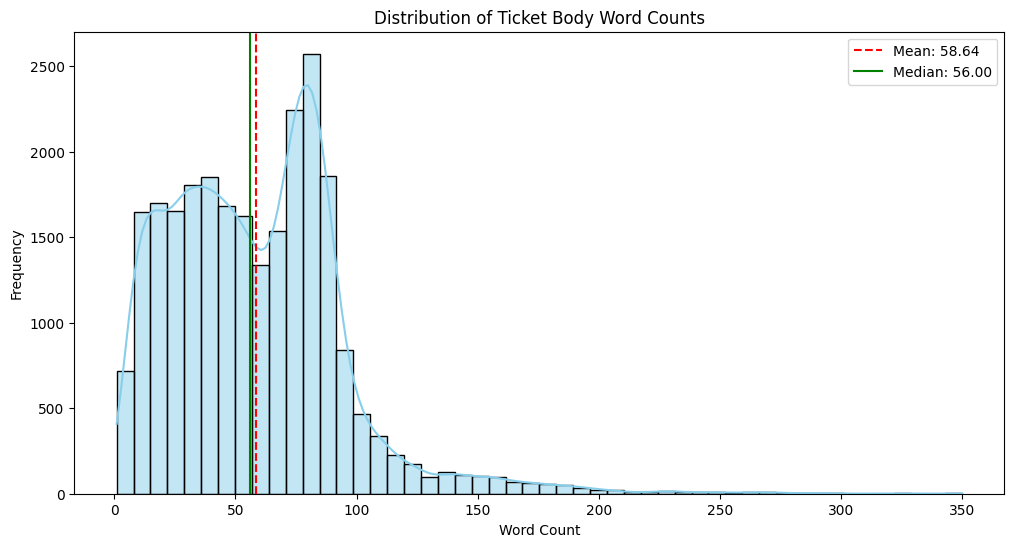

/tmp/ipykernel_3396/3820710864.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df['word_count'], palette='pastel')


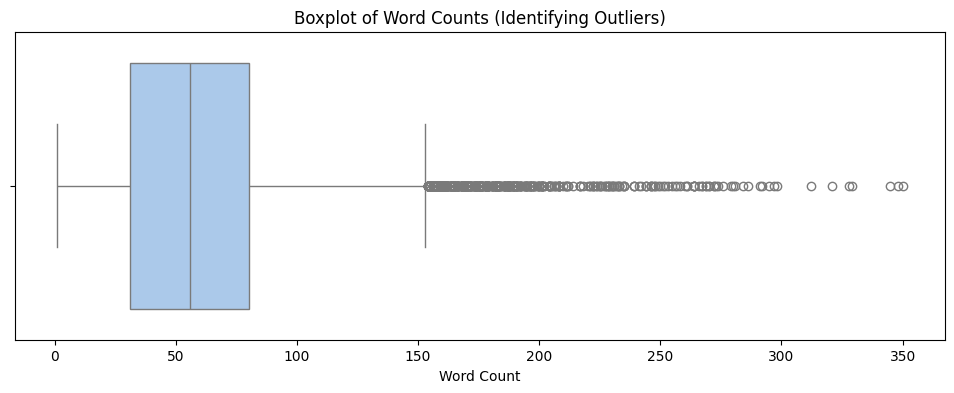

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate word counts handling the missing value
df['word_count'] = df['Body'].fillna('').apply(lambda x: len(str(x).split()))

# 2. Retrieve descriptive statistics
word_count_stats = df['word_count'].describe()
print('--- Word Count Statistics ---')
print(word_count_stats)

# 3. Visualize the distribution
plt.figure(figsize=(12, 6))

# Main Histogram
sns.histplot(df['word_count'], bins=50, kde=True, color='skyblue')
plt.title('Distribution of Ticket Body Word Counts')
plt.xlabel('Word Count')
plt.ylabel('Frequency')

# Add mean and median lines for context
plt.axvline(df['word_count'].mean(), color='red', linestyle='--', label=f'Mean: {df["word_count"].mean():.2f}')
plt.axvline(df['word_count'].median(), color='green', linestyle='-', label=f'Median: {df["word_count"].median():.2f}')
plt.legend()

plt.show()

# 4. Boxplot to highlight outliers
plt.figure(figsize=(12, 4))
sns.boxplot(x=df['word_count'], palette='pastel')
plt.title('Boxplot of Word Counts (Identifying Outliers)')
plt.xlabel('Word Count')
plt.show()

In [ ]:
df['word_count'] = df['Body'].apply(lambda x: len(str(x).split()))

short_rows = df[df['word_count'] < 4].copy()

print("Shape of rows with less than 4 words:", short_rows.shape)

display(short_rows[['Body', 'word_count','Department']].head(20))

Shape of rows with less than 4 words: (92, 6)


,Body,word_count,Department
553,Requesting Assistance,2,Product Support
706,Our system,2,Technical Support
995,Assistance Needed,2,Technical Support
1276,Requesting assistance,2,Product Support
1772,Improve investment procedures,3,IT Support
2760,Seeking assistance,2,Product Support
3987,Connection problem,2,Technical Support
4138,Requesting resolution,2,Customer Service
4144,Possible solution,2,Technical Support
4199,Problem with connectivity,3,Technical Support


In [ ]:
pd.set_option('display.max_colwidth', None)

display(short_rows[['Body', 'word_count','Department']])

,Body,word_count,Department
553,Requesting Assistance,2,Product Support
706,Our system,2,Technical Support
995,Assistance Needed,2,Technical Support
1276,Requesting assistance,2,Product Support
1772,Improve investment procedures,3,IT Support
...,...,...,...
23157,Subpar audience interaction,3,Product Support
24605,Conflicting network configurations.,3,IT Support
24880,Need immediate assistance!,3,IT Support
24912,Further clarification needed.,3,Billing and Payments


In [ ]:
df['word_count'] = df['Body'].apply(lambda x: len(str(x).split()))

short_rows = df[df['word_count'] < 3].copy()

print("Shape of rows with less than 3 words:", short_rows.shape)

display(short_rows[['Body', 'word_count','Department']].head(20))

Shape of rows with less than 3 words: (45, 6)


,Body,word_count,Department
553,Requesting Assistance,2,Product Support
706,Our system,2,Technical Support
995,Assistance Needed,2,Technical Support
1276,Requesting assistance,2,Product Support
2760,Seeking assistance,2,Product Support
3987,Connection problem,2,Technical Support
4138,Requesting resolution,2,Customer Service
4144,Possible solution,2,Technical Support
4213,Connectivity problem,2,Technical Support
4612,System,1,Technical Support


In [ ]:
pd.set_option('display.max_colwidth', None)

display(short_rows[['Body', 'word_count','Department']])

,Body,word_count,Department
553,Requesting Assistance,2,Product Support
706,Our system,2,Technical Support
995,Assistance Needed,2,Technical Support
1276,Requesting assistance,2,Product Support
2760,Seeking assistance,2,Product Support
3987,Connection problem,2,Technical Support
4138,Requesting resolution,2,Customer Service
4144,Possible solution,2,Technical Support
4213,Connectivity problem,2,Technical Support
4612,System,1,Technical Support


## PII Placeholder Detection



In [ ]:
import pandas as pd
import re
from collections import Counter

body_text = df['Body'].fillna('')


underscore_pattern = r'\b[a-zA-Z]+_[a-zA-Z]+\b'

bracket_pattern = r'\[.*?\]'

discovered_placeholders = []

for text in body_text:
    discovered_placeholders.extend(re.findall(underscore_pattern, text))
    discovered_placeholders.extend(re.findall(bracket_pattern, text))

placeholder_counts = Counter(discovered_placeholders)

print('--- Automatically Detected PII & Placeholders ---')
for placeholder, count in placeholder_counts.most_common(10):
    print(f'Placeholder "{placeholder}": {count} occurrences')


combined_pattern = f'({underscore_pattern}|{bracket_pattern})'
total_with_pii = body_text.str.contains(combined_pattern, regex=True).sum()

print(f'\nTotal tickets with at least one placeholder: {total_with_pii}')
print(f'Percentage of dataset with placeholders: {(total_with_pii / len(df)) * 100:.2f}%')

--- Automatically Detected PII & Placeholders ---
Placeholder "[Your Name]": 891 occurrences
Placeholder "tel_num": 765 occurrences
Placeholder "acc_num": 425 occurrences
Placeholder "nameacc_num": 64 occurrences
Placeholder "nametel_num": 54 occurrences
Placeholder "order_num": 28 occurrences
Placeholder "email_address": 20 occurrences
Placeholder "company_name": 20 occurrences
Placeholder "acc_numPhone": 14 occurrences
Placeholder "comtel_num": 13 occurrences


/tmp/ipykernel_3396/1573413729.py:35: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  total_with_pii = body_text.str.contains(combined_pattern, regex=True).sum()



Total tickets with at least one placeholder: 1945
Percentage of dataset with placeholders: 7.71%


دا بيحسب الكلمات المتكرره ف كل تيكت ومدي التكرار فيها


**Top Keywords per Department**

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd

df_clean = df[['Body', 'Department']].dropna()

vectorizer = TfidfVectorizer(max_features=1000, stop_words='english')
X = vectorizer.fit_transform(df_clean['Body'])

feature_names = vectorizer.get_feature_names_out()

tfidf_df = pd.DataFrame(X.toarray(), columns=feature_names)
tfidf_df['Department'] = df_clean['Department'].values

top_words_per_dept = {}

for dept in tfidf_df['Department'].unique():
    subset = tfidf_df[tfidf_df['Department'] == dept]
    mean_scores = subset.drop(columns=['Department']).mean()
    top_words = mean_scores.sort_values(ascending=False).head(10)
    top_words_per_dept[dept] = top_words

for dept, words in top_words_per_dept.items():
    print(f"\n=== {dept} ===")
    print(words)


=== Technical Support ===
data          0.054310
issue         0.053767
software      0.043007
problem       0.037282
support       0.032673
assistance    0.032123
security      0.030962
issues        0.029735
resolve       0.027887
analytics     0.027486
dtype: float64

=== Returns and Exchanges ===
data           0.061550
investment     0.038411
security       0.037764
software       0.034485
information    0.033957
issue          0.033439
analytics      0.030780
support        0.030288
appreciate     0.029749
provide        0.029595
dtype: float64

=== Billing and Payments ===
billing        0.117963
payment        0.086566
information    0.051376
provide        0.045595
details        0.043187
support        0.040897
data           0.037956
services       0.037450
available      0.034847
appreciate     0.033999
dtype: float64

=== Sales and Pre-Sales ===
data           0.054714
information    0.046740
provide        0.040996
integration    0.038525
details        0.038328
support 

In [ ]:
import pandas as pd
import re
from collections import Counter

# ══════════════════════════════════════════════════════════════
# Analysis: Why does "data" appear as top keyword in ALL departments?
# ══════════════════════════════════════════════════════════════

bodies = df['Body'].dropna().str.lower()

# ─── 1. How common is "data"? ───
total_with_data = bodies.str.contains(r'\bdata\b').sum()
print("=" * 65)
print(f'  "data" appears in {total_with_data} / {len(bodies)} tickets ({total_with_data/len(bodies)*100:.1f}%)')
print("=" * 65)

# ─── 2. "data" frequency per department ───
print("\n── Frequency of 'data' per Department ──\n")
print(f"  {'Department':<40} {'Has data':>10} {'Total':>8} {'%':>8}")
print("  " + "─" * 68)

for dept in df['Department'].value_counts().index:
    subset = df[df['Department'] == dept]['Body'].dropna().str.lower()
    has = subset.str.contains(r'\bdata\b').sum()
    pct = has / len(subset) * 100
    bar = "█" * int(pct / 2)
    print(f"  {dept:<40} {has:>10} {len(subset):>8} {pct:>7.1f}%  {bar}")

# ─── 3. Context: What words come with "data"? ───
after = []
before = []
for body in bodies:
    after.extend(re.findall(r'\bdata\s+(\w+)', body))
    before.extend(re.findall(r'(\w+)\s+data\b', body))

# filter out stopwords from "before" list
stops = {'the', 'a', 'an', 'in', 'of', 'and', 'with', 'on', 'to', 'for', 'our', 'my', 'is', 'this', 's'}
before_clean = [w for w in before if w not in stops]

print("\n── Most Common Phrases: 'data ___' ──\n")
for word, count in Counter(after).most_common(10):
    print(f'  "data {word}"  →  {count} times')

print("\n── Most Common Phrases: '___ data' ──\n")
for word, count in Counter(before_clean).most_common(10):
    print(f'  "{word} data"  →  {count} times')

# ─── 4. Show real samples per department ───
print("\n" + "=" * 65)
print("  REAL SAMPLES: How 'data' is used in each department")
print("=" * 65)

for dept in df['Department'].value_counts().index:
    subset = df[df['Department'] == dept]
    has_data = subset[subset['Body'].str.contains(r'\bdata\b', case=False, na=False)]

    if len(has_data) == 0:
        continue

    samples = has_data.sample(min(2, len(has_data)), random_state=42)

    print(f"\n┌─── {dept} ───")
    for _, row in samples.iterrows():
        sentences = re.split(r'[.!?]', row['Body'])
        data_sent = [s.strip() for s in sentences if re.search(r'\bdata\b', s, re.IGNORECASE)]
        if data_sent:
            sent = data_sent[0][:150]
            # highlight
            sent = re.sub(r'\b(data)\b', r'**\1**', sent, flags=re.IGNORECASE)
            print(f"│  → \"{sent}\"")
    print("└" + "─" * 60)



  "data" appears in 10564 / 25222 tickets (41.9%)

── Frequency of 'data' per Department ──

  Department                                 Has data    Total        %
  ────────────────────────────────────────────────────────────────────
  Technical Support                              3285     7345    44.7%  ██████████████████████
  Product Support                                2056     4670    44.0%  ██████████████████████
  Customer Service                               1700     3789    44.9%  ██████████████████████
  IT Support                                     1186     3009    39.4%  ███████████████████
  Billing and Payments                            772     2563    30.1%  ███████████████
  Returns and Exchanges                           549     1243    44.2%  ██████████████████████
  Service Outages and Maintenance                 338     1000    33.8%  ████████████████
  Sales and Pre-Sales                             313      768    40.8%  ████████████████████
  Human Resour

In [ ]:
# ============================================================
# Simple bigram check for the term "data"
# Purpose: justify adding bigrams alongside unigrams
# ============================================================

from sklearn.feature_extraction.text import CountVectorizer
import numpy as np

analysis_df = df_clean[['Body', 'Department']].dropna().copy()
analysis_df['Body'] = analysis_df['Body'].astype(str)

vectorizer = CountVectorizer(
    ngram_range=(1, 2),
    stop_words='english',
    min_df=2
)

X = vectorizer.fit_transform(analysis_df['Body'])
X_binary = (X > 0).astype(int)

vocab = vectorizer.vocabulary_
features = vectorizer.get_feature_names_out()
departments = sorted(analysis_df['Department'].unique())


def simple_term_summary(term):
    if term not in vocab:
        return None

    term_idx = vocab[term]
    term_present = np.asarray(X_binary[:, term_idx].todense()).ravel()

    dept_counts = {}

    for dept in departments:
        mask = analysis_df['Department'].values == dept
        dept_counts[dept] = int(term_present[mask].sum())

    total_count = sum(dept_counts.values())

    if total_count == 0:
        return None

    departments_present = sum(count > 0 for count in dept_counts.values())
    top_department = max(dept_counts, key=dept_counts.get)
    top_count = dept_counts[top_department]
    top_share = (top_count / total_count) * 100

    return {
        "term": term,
        "total_count": total_count,
        "departments_present": departments_present,
        "top_department": top_department,
        "top_share": top_share
    }


# Summary for unigram "data"
data_summary = simple_term_summary("data")

print("UNIGRAM CHECK")
print("-------------")
print(
    f"'data' appears in {data_summary['total_count']} documents "
    f"across {data_summary['departments_present']} departments."
)
print(
    f"Its largest share is in {data_summary['top_department']} "
    f"({data_summary['top_share']:.1f}%)."
)

# Find bigrams containing "data"
data_bigrams = [
    term for term in features
    if " " in term and "data" in term.split()
]

bigram_summaries = []

for bigram in data_bigrams:
    summary = simple_term_summary(bigram)
    if summary is not None:
        bigram_summaries.append(summary)

# Keep useful examples:
# 1) more concentrated than unigram data
# 2) or present in fewer departments than unigram data
useful_bigrams = [
    item for item in bigram_summaries
    if item["top_share"] > data_summary["top_share"]
    or item["departments_present"] < data_summary["departments_present"]
]

# Sort by strongest concentration, then frequency
useful_bigrams = sorted(
    useful_bigrams,
    key=lambda x: (x["top_share"], x["total_count"]),
    reverse=True
)

print("\nBIGRAM EXAMPLES CONTAINING 'data'")
print("---------------------------------")

for item in useful_bigrams[:5]:
    print(
        f"'{item['term']}' appears in {item['total_count']} documents "
        f"across {item['departments_present']} departments; "
        f"largest share: {item['top_department']} "
        f"({item['top_share']:.1f}%)."
    )

print("\nCONCLUSION")
print("----------")
print(
    "The unigram 'data' is broadly distributed, while some bigrams containing "
    "'data' are more concentrated in specific departments. This supports "
    "including bigrams in the TF-IDF representation."
)

UNIGRAM CHECK
-------------
'data' appears in 10564 documents across 10 departments.
Its largest share is in Technical Support (31.1%).

BIGRAM EXAMPLES CONTAINING 'data'
---------------------------------
'billing data' appears in 23 documents across 1 departments; largest share: Billing and Payments (100.0%).
'data sql' appears in 7 documents across 1 departments; largest share: Product Support (100.0%).
'employee data' appears in 7 documents across 1 departments; largest share: Human Resources (100.0%).
'complex data' appears in 6 documents across 1 departments; largest share: Product Support (100.0%).
'conflicts data' appears in 6 documents across 1 departments; largest share: Customer Service (100.0%).

CONCLUSION
----------
The unigram 'data' is broadly distributed, while some bigrams containing 'data' are more concentrated in specific departments. This supports including bigrams in the TF-IDF representation.


Vocabulary BEFORE stopword removal: 6,886
Vocabulary AFTER stopword removal:  6,643
Stopwords removed: 243


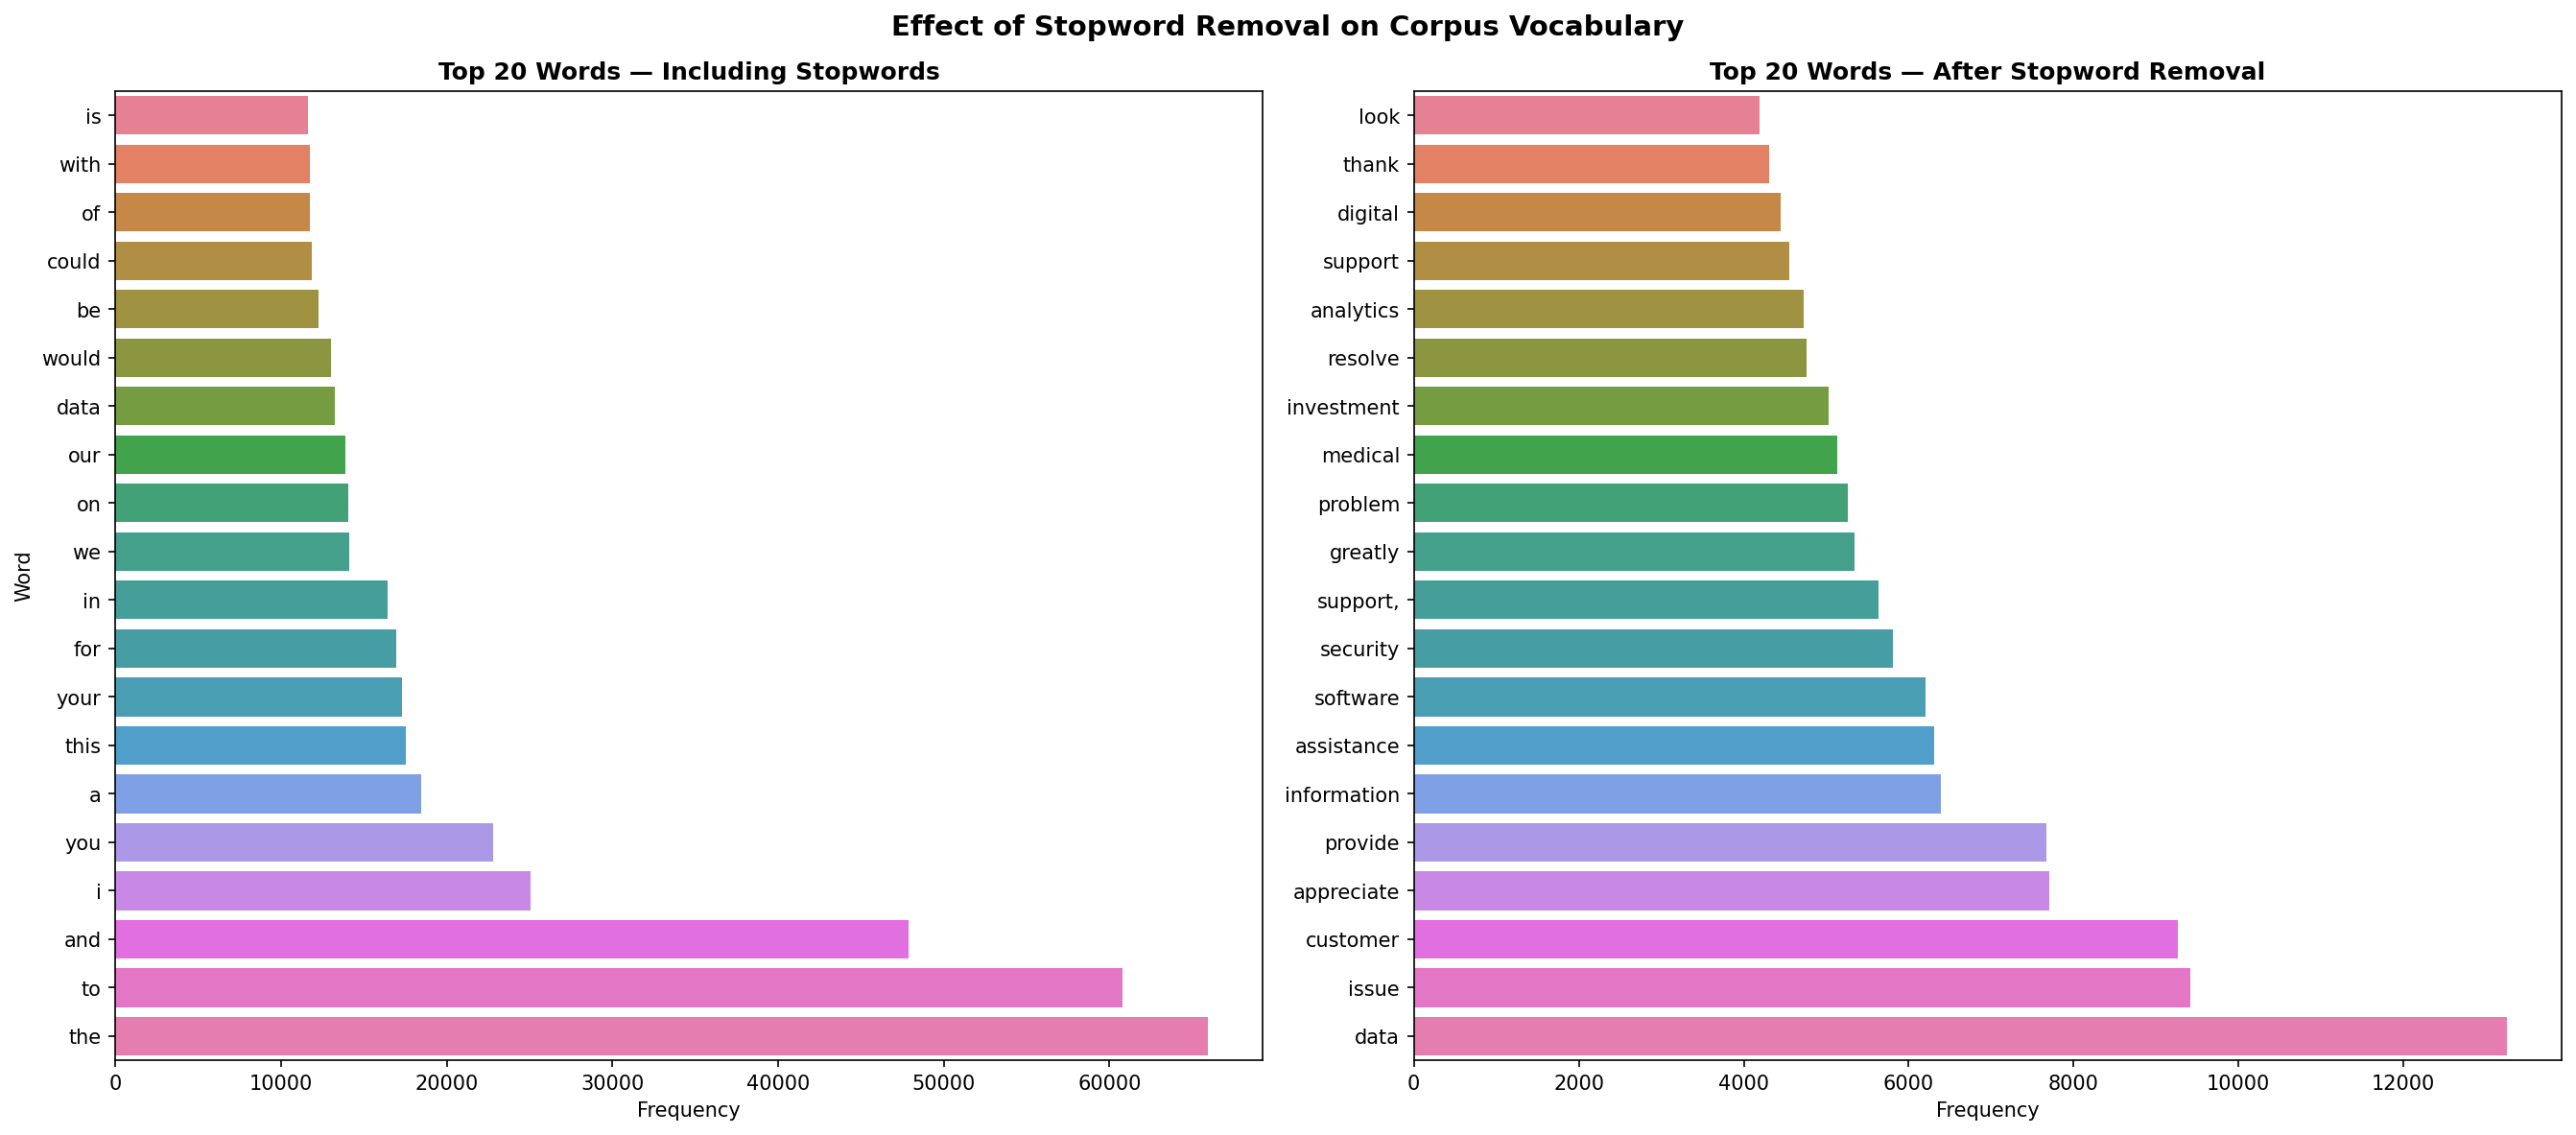

In [ ]:
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ══════════════════════════════════════════════════════════════
# Vocabulary Size Analysis
# ══════════════════════════════════════════════════════════════

# Vocabulary BEFORE stopwords
vec_raw = CountVectorizer()
vec_raw.fit(df['Body'].dropna())

vocab_before = len(vec_raw.vocabulary_)

# Vocabulary AFTER stopwords
vec_clean = CountVectorizer(stop_words='english')
vec_clean.fit(df['Body'].dropna())

vocab_after = len(vec_clean.vocabulary_)

print(f"Vocabulary BEFORE stopword removal: {vocab_before:,}")
print(f"Vocabulary AFTER stopword removal:  {vocab_after:,}")
print(f"Stopwords removed: {vocab_before - vocab_after:,}")

# ══════════════════════════════════════════════════════════════
# Raw Frequency (WITH stopwords)
# ══════════════════════════════════════════════════════════════

all_words_raw = " ".join(df['Body'].dropna()).lower().split()

raw_counts = Counter(all_words_raw)

top_raw = pd.DataFrame(
    raw_counts.most_common(20),
    columns=['Word', 'Freq']
).sort_values('Freq', ascending=True)

# ══════════════════════════════════════════════════════════════
# Meaningful Frequency (WITHOUT stopwords)
# ══════════════════════════════════════════════════════════════

meaningful_words = [
    w for w in all_words_raw
    if w not in ENGLISH_STOP_WORDS and len(w) > 2
]

meaningful_counts = Counter(meaningful_words)

meaningful_df = pd.DataFrame(
    meaningful_counts.most_common(20),
    columns=['Word', 'Frequency']
)

meaningful_df_plot = meaningful_df.sort_values(
    'Frequency',
    ascending=True
)

# ══════════════════════════════════════════════════════════════
# Side-by-Side Visualization
# ══════════════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 2, figsize=(18, 8), dpi=150)

# Left plot
sns.barplot(
    data=top_raw,
    x='Freq',
    y='Word',
    hue='Word',
    legend=False,
    ax=axes[0],
)

axes[0].set_title(
    'Top 20 Words — Including Stopwords',
    fontweight='bold'
)

axes[0].set_xlabel('Frequency')

# Right plot
sns.barplot(
    data=meaningful_df_plot,
    x='Frequency',
    y='Word',
    hue='Word',
    legend=False,
    ax=axes[1],
)

axes[1].set_title(
    'Top 20 Words — After Stopword Removal',
    fontweight='bold'
)

axes[1].set_xlabel('Frequency')
axes[1].set_ylabel('')

plt.suptitle(
    'Effect of Stopword Removal on Corpus Vocabulary',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()

plt.savefig(
    'freq_before_after_stopwords.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

TF-IDF similarity matrix built successfully.
Department                       Billing and Payments  Customer Service  General Inquiry  Human Resources  IT Support  Product Support  Returns and Exchanges  Sales and Pre-Sales  Service Outages and Maintenance  Technical Support
Department                                                                                                                                                                                                                            
Billing and Payments                            1.000             0.715            0.632            0.669       0.651            0.674                  0.700                0.684                            0.548              0.648
Customer Service                                0.715             1.000            0.929            0.917       0.917            0.955                  0.954                0.938                            0.731              0.904
General Inquiry                

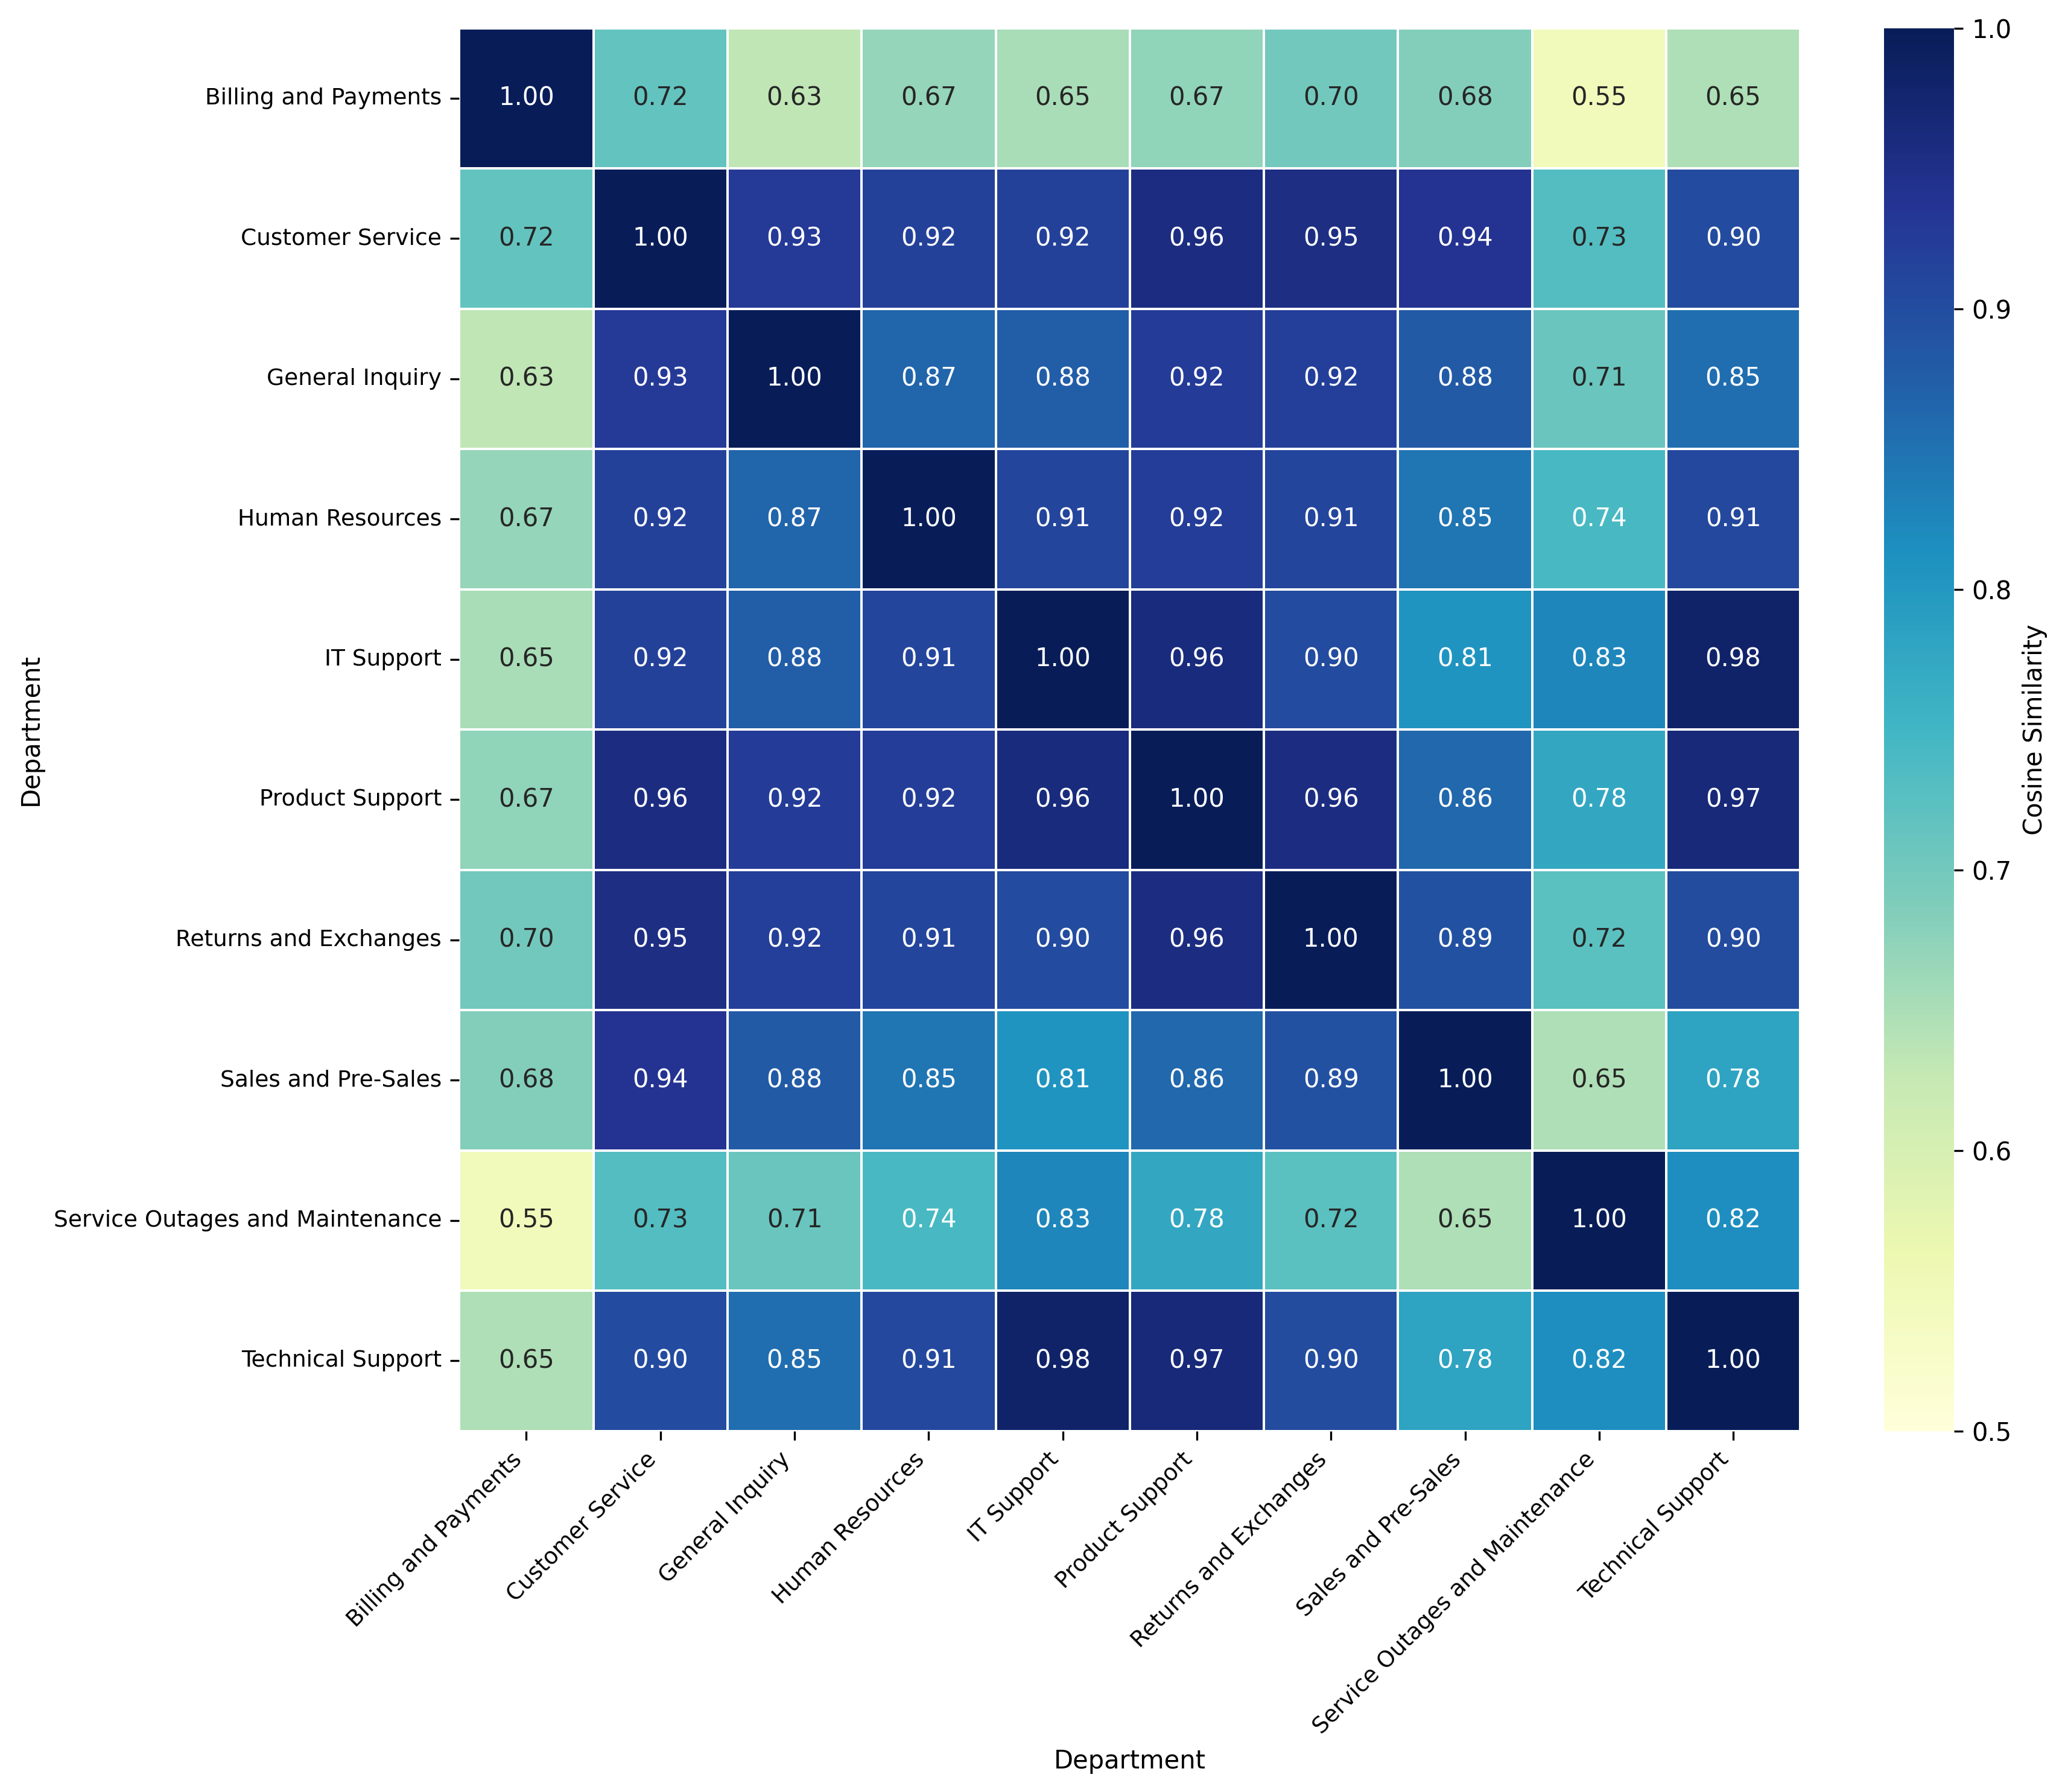

Saved: tfidf_similarity_heatmap.png


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# ─── Step 1: Re-build TF-IDF ───
df_clean = df[['Body', 'Department']].dropna().copy()

vectorizer = TfidfVectorizer(max_features=1000, stop_words='english')
X = vectorizer.fit_transform(df_clean['Body'])
feature_names = vectorizer.get_feature_names_out()

tfidf_df = pd.DataFrame(X.toarray(), columns=feature_names)
tfidf_df['Department'] = df_clean['Department'].values

# ─── Step 2: Compute similarity ───
dept_vectors = tfidf_df.groupby('Department').mean()
similarity_matrix = cosine_similarity(dept_vectors)
sim_df = pd.DataFrame(
    similarity_matrix,
    index=dept_vectors.index,
    columns=dept_vectors.index
)

print("TF-IDF similarity matrix built successfully.")
print(sim_df.round(3).to_string())

# ─── Step 3: Plot heatmap ───
fig, ax = plt.subplots(figsize=(12, 10), dpi=300)

sns.heatmap(
    sim_df,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    vmin=0.5,
    vmax=1.0,
    linewidths=0.5,
    ax=ax,
    cbar_kws={'label': 'Cosine Similarity'},
    annot_kws={"size": 10}
)


ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=9)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=9)

plt.tight_layout()
plt.savefig('tfidf_similarity_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved: tfidf_similarity_heatmap.png")

Step 1 Done: Text cleaned + stopwords removed
Sample: dear customer support team writing report significant problem centralized account management portal ...

Step 2 Done: Created representative text for 10 departments


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Encoded: Billing and Payments
  Encoded: Customer Service
  Encoded: General Inquiry
  Encoded: Human Resources
  Encoded: IT Support
  Encoded: Product Support
  Encoded: Returns and Exchanges
  Encoded: Sales and Pre-Sales
  Encoded: Service Outages and Maintenance
  Encoded: Technical Support

Step 3 Done: Generated semantic embeddings (shape: (10, 384))

── Semantic Similarity Matrix ──

                                 Billing and Payments  Customer Service  General Inquiry  Human Resources  IT Support  Product Support  Returns and Exchanges  Sales and Pre-Sales  Service Outages and Maintenance  Technical Support
Billing and Payments                            1.000             0.868            0.857            0.840       0.830            0.845                  0.877                0.854                            0.810              0.814
Customer Service                                0.868             1.000            0.985            0.968       0.973            0.983       

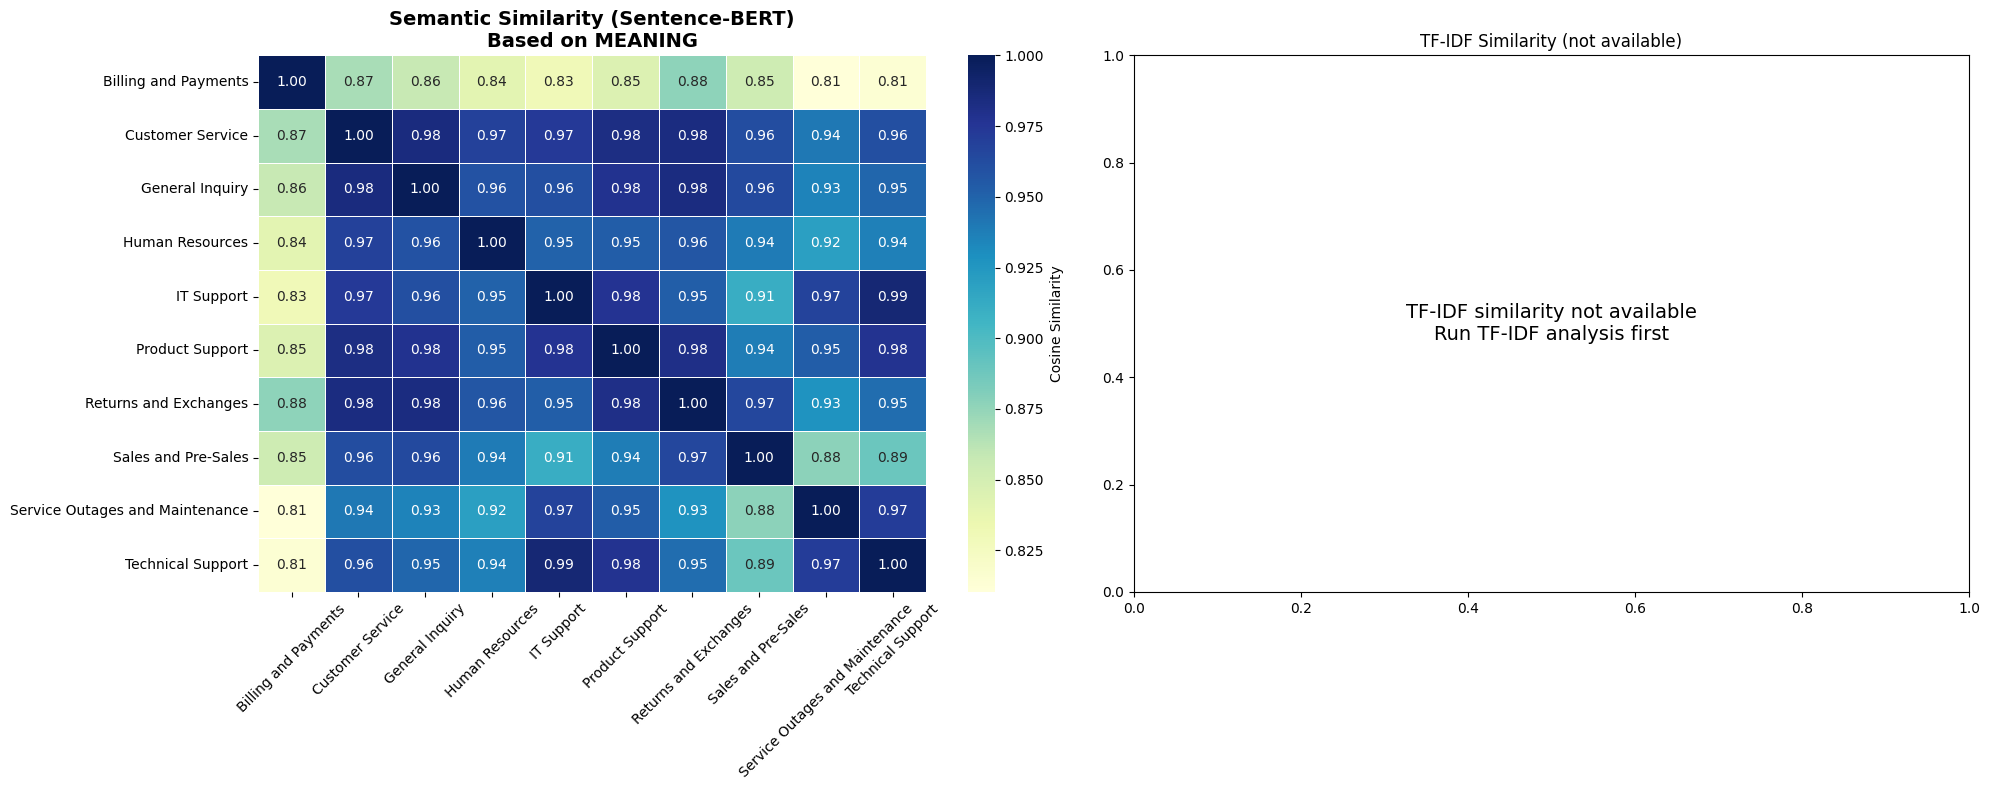


  KEY COMPARISON: Semantic vs TF-IDF Similarity

Cannot compare — run TF-IDF similarity analysis first


In [ ]:
# ══════════════════════════════════════════════════════════════
# Semantic Similarity Between Departments (using Sentence-BERT)
# ══════════════════════════════════════════════════════════════

# --- Step 0: Install (run once) ---
# !pip install sentence-transformers

from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# ─── Step 1: Prepare text (remove stopwords first, as the doctor requested) ───

df_sem = df[['Body', 'Department']].dropna().copy()

def clean_for_semantic(text):
    text = text.lower()
    text = re.sub(r'<[^>]+>', ' ', text)           # HTML
    text = re.sub(r'http\S+', ' ', text)            # URLs
    text = re.sub(r'\[.*?\]', ' ', text)            # [Your Name]
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)        # special chars
    words = text.split()
    words = [w for w in words if w not in ENGLISH_STOP_WORDS and len(w) > 2]
    return " ".join(words)

df_sem['clean'] = df_sem['Body'].apply(clean_for_semantic)

print("Step 1 Done: Text cleaned + stopwords removed")
print(f"Sample: {df_sem['clean'].iloc[0][:100]}...")

# ─── Step 2: Create one representative text per department ───
# We concatenate a random sample of tickets per department
# (using all tickets would be too slow)

dept_texts = {}
for dept in df_sem['Department'].unique():
    subset = df_sem[df_sem['Department'] == dept]['clean']
    # Sample up to 500 tickets per department for speed
    sample = subset.sample(min(500, len(subset)), random_state=42)
    dept_texts[dept] = " ".join(sample.values)

print(f"\nStep 2 Done: Created representative text for {len(dept_texts)} departments")

# ─── Step 3: Generate Semantic Embeddings using Sentence-BERT ───

model = SentenceTransformer('all-MiniLM-L6-v2')  # lightweight, fast, good quality

# For long texts, we split into chunks and average
def get_embedding(text, model, max_length=500):
    words = text.split()
    chunks = []
    for i in range(0, len(words), max_length):
        chunk = " ".join(words[i:i+max_length])
        chunks.append(chunk)
    embeddings = model.encode(chunks)
    return np.mean(embeddings, axis=0)

dept_names = sorted(dept_texts.keys())
dept_embeddings = []

for dept in dept_names:
    emb = get_embedding(dept_texts[dept], model)
    dept_embeddings.append(emb)
    print(f"  Encoded: {dept}")

dept_embeddings = np.array(dept_embeddings)
print(f"\nStep 3 Done: Generated semantic embeddings (shape: {dept_embeddings.shape})")

# ─── Step 4: Calculate Semantic Cosine Similarity ───

sem_similarity = cosine_similarity(dept_embeddings)
sem_df = pd.DataFrame(sem_similarity, index=dept_names, columns=dept_names)

print("\n── Semantic Similarity Matrix ──\n")
print(sem_df.round(3).to_string())

# ─── Step 5: Visualize ───

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Left: Semantic Similarity
sns.heatmap(
    sem_df, annot=True, fmt=".2f", cmap="YlGnBu",
    linewidths=0.5, ax=axes[0],
    cbar_kws={'label': 'Cosine Similarity'}
)
axes[0].set_title("Semantic Similarity (Sentence-BERT)\nBased on MEANING",
                   fontsize=14, fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)

# Right: TF-IDF Similarity (for comparison, reusing earlier sim_df if available)
try:
    sns.heatmap(
        sim_df, annot=True, fmt=".2f", cmap="YlOrRd",
        linewidths=0.5, ax=axes[1],
        cbar_kws={'label': 'Cosine Similarity'}
    )
    axes[1].set_title("TF-IDF Similarity (Word-based)\nBased on SHARED WORDS",
                       fontsize=14, fontweight='bold')
    axes[1].tick_params(axis='x', rotation=45)
except:
    axes[1].text(0.5, 0.5, 'TF-IDF similarity not available\nRun TF-IDF analysis first',
                 ha='center', va='center', fontsize=14)
    axes[1].set_title("TF-IDF Similarity (not available)")

plt.tight_layout()
plt.savefig('semantic_vs_tfidf_similarity.png', dpi=300, bbox_inches='tight')
plt.show()

# ─── Step 6: Key Differences ───

print("\n" + "=" * 65)
print("  KEY COMPARISON: Semantic vs TF-IDF Similarity")
print("=" * 65)

try:
    diff = sem_df.values - sim_df.values
    diff_df = pd.DataFrame(diff, index=dept_names, columns=dept_names)

    # Find biggest differences
    pairs = []
    for i in range(len(dept_names)):
        for j in range(i+1, len(dept_names)):
            pairs.append({
                'Dept A': dept_names[i],
                'Dept B': dept_names[j],
                'TF-IDF Sim': sim_df.iloc[i, j],
                'Semantic Sim': sem_df.iloc[i, j],
                'Difference': sem_df.iloc[i, j] - sim_df.iloc[i, j]
            })

    pairs_df = pd.DataFrame(pairs).sort_values('Difference', key=abs, ascending=False)

    print("\nPairs with BIGGEST difference between Semantic and TF-IDF:\n")
    print(pairs_df.head(10).to_string(index=False))

    print("\n── Interpretation ──")
    print("• Positive difference = Semantic finds MORE similarity than TF-IDF")
    print("  (departments use different words but talk about similar topics)")
    print("• Negative difference = Semantic finds LESS similarity than TF-IDF")
    print("  (departments share words but have different meanings)")
except:
    print("\nCannot compare — run TF-IDF similarity analysis first")

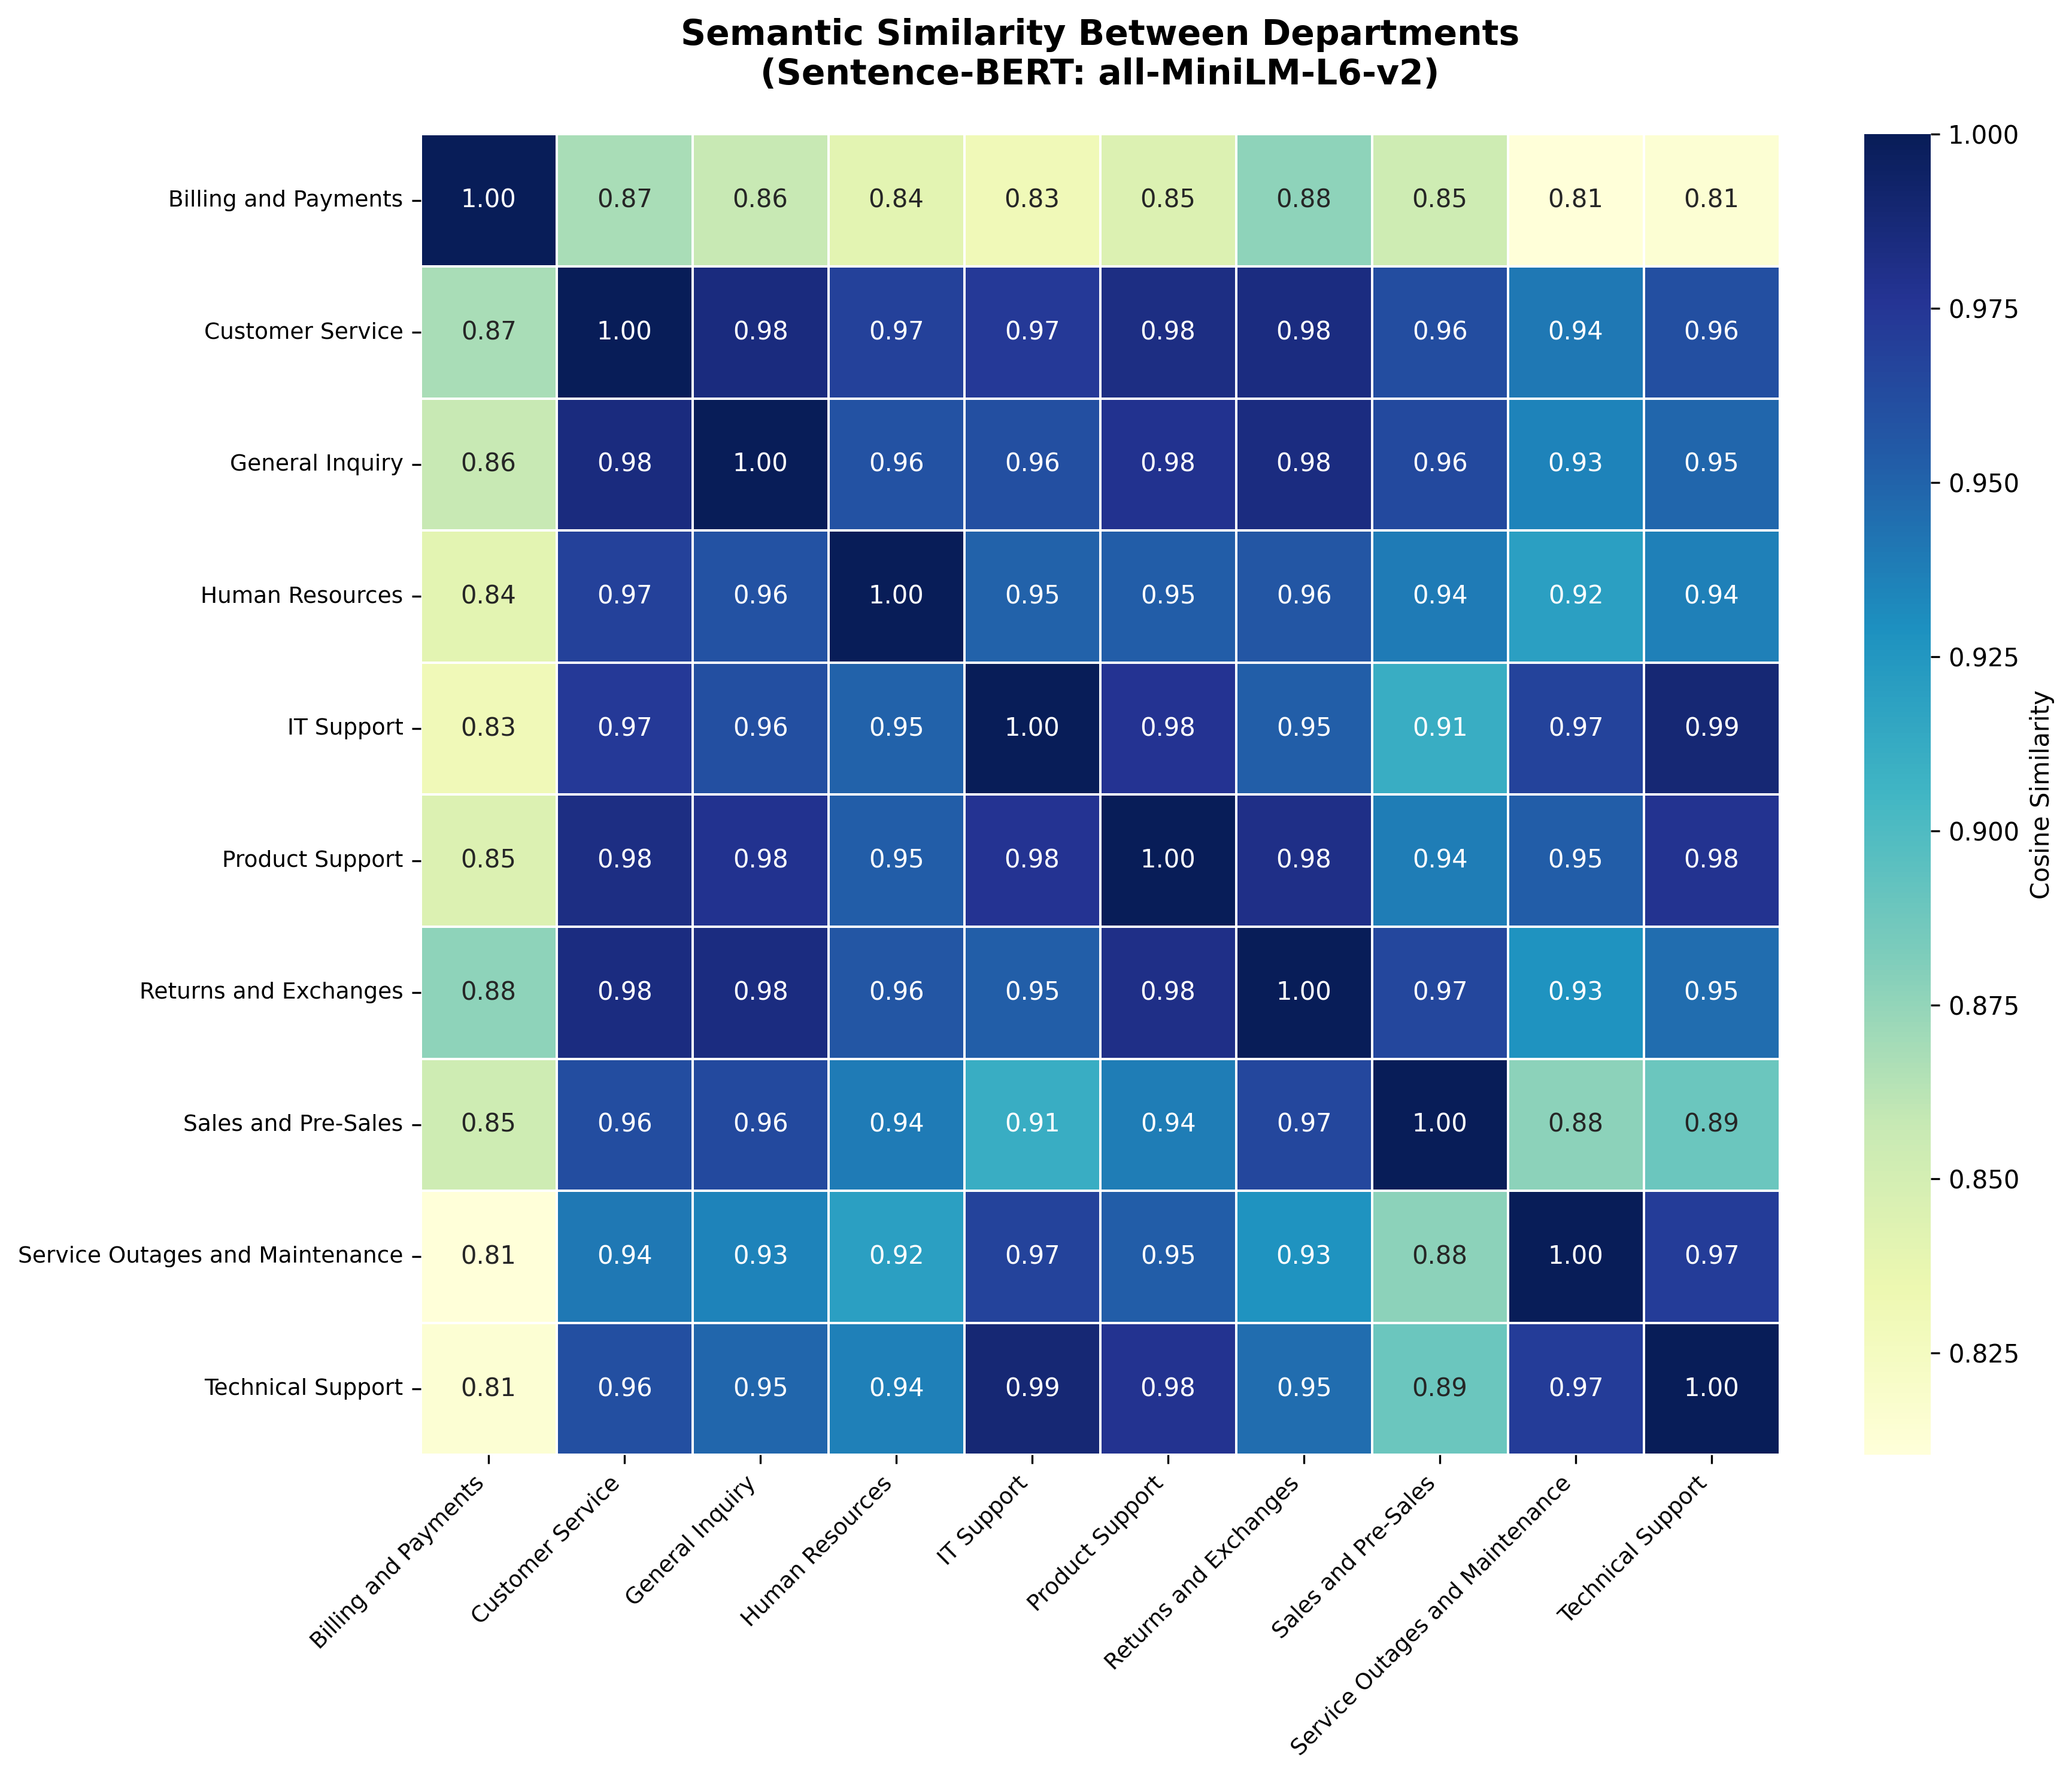

Saved: semantic_similarity_heatmap.png


In [ ]:
# ─── Save Semantic heatmap ALONE ───
fig_sem, ax_sem = plt.subplots(figsize=(12, 10), dpi=300)

sns.heatmap(
    sem_df,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5,
    ax=ax_sem,
    cbar_kws={'label': 'Cosine Similarity'},
    annot_kws={"size": 10}
)

ax_sem.set_title("Semantic Similarity Between Departments\n(Sentence-BERT: all-MiniLM-L6-v2)",
                  fontsize=14, fontweight='bold', pad=20)

# Fix x-axis labels
ax_sem.set_xticklabels(
    ax_sem.get_xticklabels(),
    rotation=45,
    ha='right',
    fontsize=9
)

# Fix y-axis labels
ax_sem.set_yticklabels(
    ax_sem.get_yticklabels(),
    rotation=0,
    fontsize=9
)

plt.tight_layout()
plt.savefig('semantic_similarity_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved: semantic_similarity_heatmap.png")

***prepossing***

In [ ]:
df.isna().sum()

,0
Body,0
Department,0
Priority,0
Tags,0
Tags_cleaned,0


In [ ]:
import pandas as pd
import re

df_ml = df[['Body', 'Department']].copy()



**lowercase**

In [ ]:
df_ml['Body_clean_ml'] = df_ml['Body'].str.lower()

display(df_ml[['Body', 'Body_clean_ml']].head(3))

,Body,Body_clean_ml
0,"Dear Customer Support Team,I am writing to report a significant problem with the centralized account management portal, which currently appears to be offline. This outage is blocking access to account settings, leading to substantial inconvenience. I have attempted to log in multiple times using different browsers and devices, but the issue persists.Could you please provide an update on the outage status and an estimated time for resolution? Also, are there any alternative ways to access and manage my account during this downtime?","dear customer support team,i am writing to report a significant problem with the centralized account management portal, which currently appears to be offline. this outage is blocking access to account settings, leading to substantial inconvenience. i have attempted to log in multiple times using different browsers and devices, but the issue persists.could you please provide an update on the outage status and an estimated time for resolution? also, are there any alternative ways to access and manage my account during this downtime?"
1,"Dear Customer Support Team,I hope this message reaches you well. I am reaching out to request detailed information about the capabilities of your smart home integration products listed on your website. As a potential customer aiming to develop a seamlessly interconnected home environment, it is essential to understand how your products interact with various smart home platforms.Could you kindly provide detailed compatibility information with popular smart home ecosystems such as Amazon Alexa, Google Assistant, and Apple?","dear customer support team,i hope this message reaches you well. i am reaching out to request detailed information about the capabilities of your smart home integration products listed on your website. as a potential customer aiming to develop a seamlessly interconnected home environment, it is essential to understand how your products interact with various smart home platforms.could you kindly provide detailed compatibility information with popular smart home ecosystems such as amazon alexa, google assistant, and apple?"
2,"Dear Customer Support Team,I hope this message finds you well. I am reaching out to request clarification about the billing and payment procedures linked to my account. Recently, I observed some inconsistencies in the charges applied and would like to ensure I fully understand the billing cycle, accepted payment options, and any potential extra charges.Firstly, I would be grateful if you could provide a detailed explanation of how the billing cycle functions. Specifically, I am interested in knowing the start and end dates.Thank you for your assistance regarding these billing inquiries.","dear customer support team,i hope this message finds you well. i am reaching out to request clarification about the billing and payment procedures linked to my account. recently, i observed some inconsistencies in the charges applied and would like to ensure i fully understand the billing cycle, accepted payment options, and any potential extra charges.firstly, i would be grateful if you could provide a detailed explanation of how the billing cycle functions. specifically, i am interested in knowing the start and end dates.thank you for your assistance regarding these billing inquiries."


In [ ]:
print('--- Missing Values Count ---')
missing_values = df.isnull().sum()
print(missing_values)

print('\n--- Duplicated Rows Count ---')
duplicate_count = df.duplicated().sum()
print(f'Total duplicate rows: {duplicate_count}')

--- Missing Values Count ---
Body          0
Department    0
Priority      0
Tags          0
wc            0
word_count    0
dtype: int64

--- Duplicated Rows Count ---
Total duplicate rows: 0


**HTML removal**

In [ ]:
html_pattern = r'<[^>]+>'

df_ml['Body_clean_ml'] = df_ml['Body_clean_ml'].str.replace(
    html_pattern, ' ', regex=True
)

display(df_ml[['Body', 'Body_clean_ml']].head(3))

,Body,Body_clean_ml
0,"Dear Customer Support Team,I am writing to report a significant problem with the centralized account management portal, which currently appears to be offline. This outage is blocking access to account settings, leading to substantial inconvenience. I have attempted to log in multiple times using different browsers and devices, but the issue persists.Could you please provide an update on the outage status and an estimated time for resolution? Also, are there any alternative ways to access and manage my account during this downtime?","dear customer support team,i am writing to report a significant problem with the centralized account management portal, which currently appears to be offline. this outage is blocking access to account settings, leading to substantial inconvenience. i have attempted to log in multiple times using different browsers and devices, but the issue persists.could you please provide an update on the outage status and an estimated time for resolution? also, are there any alternative ways to access and manage my account during this downtime?"
1,"Dear Customer Support Team,I hope this message reaches you well. I am reaching out to request detailed information about the capabilities of your smart home integration products listed on your website. As a potential customer aiming to develop a seamlessly interconnected home environment, it is essential to understand how your products interact with various smart home platforms.Could you kindly provide detailed compatibility information with popular smart home ecosystems such as Amazon Alexa, Google Assistant, and Apple?","dear customer support team,i hope this message reaches you well. i am reaching out to request detailed information about the capabilities of your smart home integration products listed on your website. as a potential customer aiming to develop a seamlessly interconnected home environment, it is essential to understand how your products interact with various smart home platforms.could you kindly provide detailed compatibility information with popular smart home ecosystems such as amazon alexa, google assistant, and apple?"
2,"Dear Customer Support Team,I hope this message finds you well. I am reaching out to request clarification about the billing and payment procedures linked to my account. Recently, I observed some inconsistencies in the charges applied and would like to ensure I fully understand the billing cycle, accepted payment options, and any potential extra charges.Firstly, I would be grateful if you could provide a detailed explanation of how the billing cycle functions. Specifically, I am interested in knowing the start and end dates.Thank you for your assistance regarding these billing inquiries.","dear customer support team,i hope this message finds you well. i am reaching out to request clarification about the billing and payment procedures linked to my account. recently, i observed some inconsistencies in the charges applied and would like to ensure i fully understand the billing cycle, accepted payment options, and any potential extra charges.firstly, i would be grateful if you could provide a detailed explanation of how the billing cycle functions. specifically, i am interested in knowing the start and end dates.thank you for your assistance regarding these billing inquiries."


In [ ]:
before_html = df_ml['Body'].str.contains(html_pattern, regex=True).sum()
after_html = df_ml['Body_clean_ml'].str.contains(html_pattern, regex=True).sum()

print("Rows with HTML before cleaning:", before_html)
print("Rows with HTML after cleaning:", after_html)

Rows with HTML before cleaning: 817
Rows with HTML after cleaning: 0


**url removal**

In [ ]:
url_pattern = r'http[s]?://\S+|www\.\S+'

df_ml['Body_clean_ml'] = df_ml['Body_clean_ml'].str.replace(
    url_pattern, ' ', regex=True
)

display(df_ml[['Body', 'Body_clean_ml']].head(3))

,Body,Body_clean_ml
0,"Dear Customer Support Team,I am writing to report a significant problem with the centralized account management portal, which currently appears to be offline. This outage is blocking access to account settings, leading to substantial inconvenience. I have attempted to log in multiple times using different browsers and devices, but the issue persists.Could you please provide an update on the outage status and an estimated time for resolution? Also, are there any alternative ways to access and manage my account during this downtime?","dear customer support team,i am writing to report a significant problem with the centralized account management portal, which currently appears to be offline. this outage is blocking access to account settings, leading to substantial inconvenience. i have attempted to log in multiple times using different browsers and devices, but the issue persists.could you please provide an update on the outage status and an estimated time for resolution? also, are there any alternative ways to access and manage my account during this downtime?"
1,"Dear Customer Support Team,I hope this message reaches you well. I am reaching out to request detailed information about the capabilities of your smart home integration products listed on your website. As a potential customer aiming to develop a seamlessly interconnected home environment, it is essential to understand how your products interact with various smart home platforms.Could you kindly provide detailed compatibility information with popular smart home ecosystems such as Amazon Alexa, Google Assistant, and Apple?","dear customer support team,i hope this message reaches you well. i am reaching out to request detailed information about the capabilities of your smart home integration products listed on your website. as a potential customer aiming to develop a seamlessly interconnected home environment, it is essential to understand how your products interact with various smart home platforms.could you kindly provide detailed compatibility information with popular smart home ecosystems such as amazon alexa, google assistant, and apple?"
2,"Dear Customer Support Team,I hope this message finds you well. I am reaching out to request clarification about the billing and payment procedures linked to my account. Recently, I observed some inconsistencies in the charges applied and would like to ensure I fully understand the billing cycle, accepted payment options, and any potential extra charges.Firstly, I would be grateful if you could provide a detailed explanation of how the billing cycle functions. Specifically, I am interested in knowing the start and end dates.Thank you for your assistance regarding these billing inquiries.","dear customer support team,i hope this message finds you well. i am reaching out to request clarification about the billing and payment procedures linked to my account. recently, i observed some inconsistencies in the charges applied and would like to ensure i fully understand the billing cycle, accepted payment options, and any potential extra charges.firstly, i would be grateful if you could provide a detailed explanation of how the billing cycle functions. specifically, i am interested in knowing the start and end dates.thank you for your assistance regarding these billing inquiries."


In [ ]:
before_url = df_ml['Body'].str.contains(url_pattern, regex=True).sum()
after_url = df_ml['Body_clean_ml'].str.contains(url_pattern, regex=True).sum()

print("Rows with URLs before cleaning:", before_url)
print("Rows with URLs after cleaning:", after_url)

Rows with URLs before cleaning: 0
Rows with URLs after cleaning: 0


**placeholders removal**


In [ ]:
import re

# === FIXED: Use specific placeholder list instead of broad underscore pattern ===
# The broad pattern r'\b[a-zA-Z]+_[a-zA-Z]+\b' can accidentally remove
# meaningful words like "real_time" or "customer_service".
# Instead, we use the specific placeholders discovered in the EDA.

known_placeholders = [
    'acc_num', 'tel_num', 'nametel_num', 'nameacc_num',
    'order_num', 'email_address', 'company_name',
    'acc_numPhone', 'comtel_num', 'numtel_num',
    'nameorder_num', 'addresstel_num'
]

bracket_pattern = r'\[.*?\]'

def remove_placeholders(text):
    # Remove [Your Name] and similar bracket placeholders
    text = re.sub(bracket_pattern, ' ', text)
    # Remove only known underscore placeholders
    for ph in known_placeholders:
        text = re.sub(r'\b' + re.escape(ph) + r'\b', ' ', text)
    return text

In [ ]:
df_ml['Body_clean_ml'] = df_ml['Body_clean_ml'].apply(remove_placeholders)

display(df_ml[['Body', 'Body_clean_ml']].head(5))

,Body,Body_clean_ml
0,"Dear Customer Support Team,I am writing to report a significant problem with the centralized account management portal, which currently appears to be offline. This outage is blocking access to account settings, leading to substantial inconvenience. I have attempted to log in multiple times using different browsers and devices, but the issue persists.Could you please provide an update on the outage status and an estimated time for resolution? Also, are there any alternative ways to access and manage my account during this downtime?","dear customer support team,i am writing to report a significant problem with the centralized account management portal, which currently appears to be offline. this outage is blocking access to account settings, leading to substantial inconvenience. i have attempted to log in multiple times using different browsers and devices, but the issue persists.could you please provide an update on the outage status and an estimated time for resolution? also, are there any alternative ways to access and manage my account during this downtime?"
1,"Dear Customer Support Team,I hope this message reaches you well. I am reaching out to request detailed information about the capabilities of your smart home integration products listed on your website. As a potential customer aiming to develop a seamlessly interconnected home environment, it is essential to understand how your products interact with various smart home platforms.Could you kindly provide detailed compatibility information with popular smart home ecosystems such as Amazon Alexa, Google Assistant, and Apple?","dear customer support team,i hope this message reaches you well. i am reaching out to request detailed information about the capabilities of your smart home integration products listed on your website. as a potential customer aiming to develop a seamlessly interconnected home environment, it is essential to understand how your products interact with various smart home platforms.could you kindly provide detailed compatibility information with popular smart home ecosystems such as amazon alexa, google assistant, and apple?"
2,"Dear Customer Support Team,I hope this message finds you well. I am reaching out to request clarification about the billing and payment procedures linked to my account. Recently, I observed some inconsistencies in the charges applied and would like to ensure I fully understand the billing cycle, accepted payment options, and any potential extra charges.Firstly, I would be grateful if you could provide a detailed explanation of how the billing cycle functions. Specifically, I am interested in knowing the start and end dates.Thank you for your assistance regarding these billing inquiries.","dear customer support team,i hope this message finds you well. i am reaching out to request clarification about the billing and payment procedures linked to my account. recently, i observed some inconsistencies in the charges applied and would like to ensure i fully understand the billing cycle, accepted payment options, and any potential extra charges.firstly, i would be grateful if you could provide a detailed explanation of how the billing cycle functions. specifically, i am interested in knowing the start and end dates.thank you for your assistance regarding these billing inquiries."
3,"Dear Support Team,I hope this message reaches you well. I am reaching out to ask about the compatibility of your products with the specific needs of marketing agencies. Our company is considering adopting these solutions to streamline our current marketing processes and wants to confirm that the products are fully compatible with the tools and platforms we currently utilize.Could you please supply detailed information regarding the compatibility of your products with popular marketing software, CRM systems, email marketing applications, and analytics platforms? Additionally, I would appreciate any relevant case studies or documentation

**boilerplate removal**

In [ ]:
# === Boilerplate Phrases ===
# Note: Removed standalone "regards" as it's too aggressive
# and could match inside meaningful sentences.
# Only using full phrases that are clearly boilerplate.

boilerplate_phrases = [
    "dear customer support team",
    "dear support team",
    "i hope this message finds you well",
    "i hope this message reaches you well",
    "thank you for your assistance",
    "thank you for your time and assistance",
    "thank you for your time",
    "thank you for your help",
    "kind regards",
    "best regards",
    "warm regards",
    "sincerely",
    "looking forward to your response",
    "i look forward to your reply",
    "could you please",
    "i would appreciate"
]

def remove_boilerplate(text):
    for phrase in boilerplate_phrases:
        text = re.sub(re.escape(phrase), ' ', text)
    return text

In [ ]:
df_ml['Body_clean_ml'] = df_ml['Body_clean_ml'].apply(remove_boilerplate)

display(df_ml[['Body', 'Body_clean_ml']].head(5))

,Body,Body_clean_ml
0,"Dear Customer Support Team,I am writing to report a significant problem with the centralized account management portal, which currently appears to be offline. This outage is blocking access to account settings, leading to substantial inconvenience. I have attempted to log in multiple times using different browsers and devices, but the issue persists.Could you please provide an update on the outage status and an estimated time for resolution? Also, are there any alternative ways to access and manage my account during this downtime?",",i am writing to report a significant problem with the centralized account management portal, which currently appears to be offline. this outage is blocking access to account settings, leading to substantial inconvenience. i have attempted to log in multiple times using different browsers and devices, but the issue persists. provide an update on the outage status and an estimated time for resolution? also, are there any alternative ways to access and manage my account during this downtime?"
1,"Dear Customer Support Team,I hope this message reaches you well. I am reaching out to request detailed information about the capabilities of your smart home integration products listed on your website. As a potential customer aiming to develop a seamlessly interconnected home environment, it is essential to understand how your products interact with various smart home platforms.Could you kindly provide detailed compatibility information with popular smart home ecosystems such as Amazon Alexa, Google Assistant, and Apple?",", . i am reaching out to request detailed information about the capabilities of your smart home integration products listed on your website. as a potential customer aiming to develop a seamlessly interconnected home environment, it is essential to understand how your products interact with various smart home platforms.could you kindly provide detailed compatibility information with popular smart home ecosystems such as amazon alexa, google assistant, and apple?"
2,"Dear Customer Support Team,I hope this message finds you well. I am reaching out to request clarification about the billing and payment procedures linked to my account. Recently, I observed some inconsistencies in the charges applied and would like to ensure I fully understand the billing cycle, accepted payment options, and any potential extra charges.Firstly, I would be grateful if you could provide a detailed explanation of how the billing cycle functions. Specifically, I am interested in knowing the start and end dates.Thank you for your assistance regarding these billing inquiries.",", . i am reaching out to request clarification about the billing and payment procedures linked to my account. recently, i observed some inconsistencies in the charges applied and would like to ensure i fully understand the billing cycle, accepted payment options, and any potential extra charges.firstly, i would be grateful if you could provide a detailed explanation of how the billing cycle functions. specifically, i am interested in knowing the start and end dates. regarding these billing inquiries."
3,"Dear Support Team,I hope this message reaches you well. I am reaching out to ask about the compatibility of your products with the specific needs of marketing agencies. Our company is considering adopting these solutions to streamline our current marketing processes and wants to confirm that the products are fully compatible with the tools and platforms we currently utilize.Could you please supply detailed information regarding the compatibility of your products with popular marketing software, CRM systems, email marketing applications, and analytics platforms? Additionally, I would appreciate any relevant case studies or documentation tailored to our use case.",", . i am reaching out to ask about the compatibility of your products with the specific needs of marketing agencies. our company is considering adopting these sol

**extra cleaning fter this removal**

In [ ]:
def normalize_text(text):
    # remove non-letters except spaces
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    # collapse multiple spaces
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df_ml['Body_clean_ml'] = df_ml['Body_clean_ml'].apply(normalize_text)

display(df_ml[['Body', 'Body_clean_ml']].head(5))

,Body,Body_clean_ml
0,"Dear Customer Support Team,I am writing to report a significant problem with the centralized account management portal, which currently appears to be offline. This outage is blocking access to account settings, leading to substantial inconvenience. I have attempted to log in multiple times using different browsers and devices, but the issue persists.Could you please provide an update on the outage status and an estimated time for resolution? Also, are there any alternative ways to access and manage my account during this downtime?",i am writing to report a significant problem with the centralized account management portal which currently appears to be offline this outage is blocking access to account settings leading to substantial inconvenience i have attempted to log in multiple times using different browsers and devices but the issue persists provide an update on the outage status and an estimated time for resolution also are there any alternative ways to access and manage my account during this downtime
1,"Dear Customer Support Team,I hope this message reaches you well. I am reaching out to request detailed information about the capabilities of your smart home integration products listed on your website. As a potential customer aiming to develop a seamlessly interconnected home environment, it is essential to understand how your products interact with various smart home platforms.Could you kindly provide detailed compatibility information with popular smart home ecosystems such as Amazon Alexa, Google Assistant, and Apple?",i am reaching out to request detailed information about the capabilities of your smart home integration products listed on your website as a potential customer aiming to develop a seamlessly interconnected home environment it is essential to understand how your products interact with various smart home platforms could you kindly provide detailed compatibility information with popular smart home ecosystems such as amazon alexa google assistant and apple
2,"Dear Customer Support Team,I hope this message finds you well. I am reaching out to request clarification about the billing and payment procedures linked to my account. Recently, I observed some inconsistencies in the charges applied and would like to ensure I fully understand the billing cycle, accepted payment options, and any potential extra charges.Firstly, I would be grateful if you could provide a detailed explanation of how the billing cycle functions. Specifically, I am interested in knowing the start and end dates.Thank you for your assistance regarding these billing inquiries.",i am reaching out to request clarification about the billing and payment procedures linked to my account recently i observed some inconsistencies in the charges applied and would like to ensure i fully understand the billing cycle accepted payment options and any potential extra charges firstly i would be grateful if you could provide a detailed explanation of how the billing cycle functions specifically i am interested in knowing the start and end dates regarding these billing inquiries
3,"Dear Support Team,I hope this message reaches you well. I am reaching out to ask about the compatibility of your products with the specific needs of marketing agencies. Our company is considering adopting these solutions to streamline our current marketing processes and wants to confirm that the products are fully compatible with the tools and platforms we currently utilize.Could you please supply detailed information regarding the compatibility of your products with popular marketing software, CRM systems, email marketing applications, and analytics platforms? Additionally, I would appreciate any relevant case studies or documentation tailored to our use case.",i am reaching out to ask about the compatibility of your products with the specific needs of marketing agencies our company is considering adopting these solutions to streamline our current marketing p

In [ ]:
df_ml.isna().sum()


,0
Body,0
Department,0
Body_clean_ml,0


**stop words removal**

  IMPACT OF STOPWORD REMOVAL
  Metric                           Before    After     Change
  ────────────────────────────────────────────────────────
  Mean word count                    57.4     31.9      -25.5
  Median word count                  55.0     31.0      -24.0
  Total words removed                                +643,254
  % of words removed                                    44.4%


/tmp/ipykernel_3396/697622950.py:48: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([before_lengths, after_lengths], labels=['Before', 'After'])


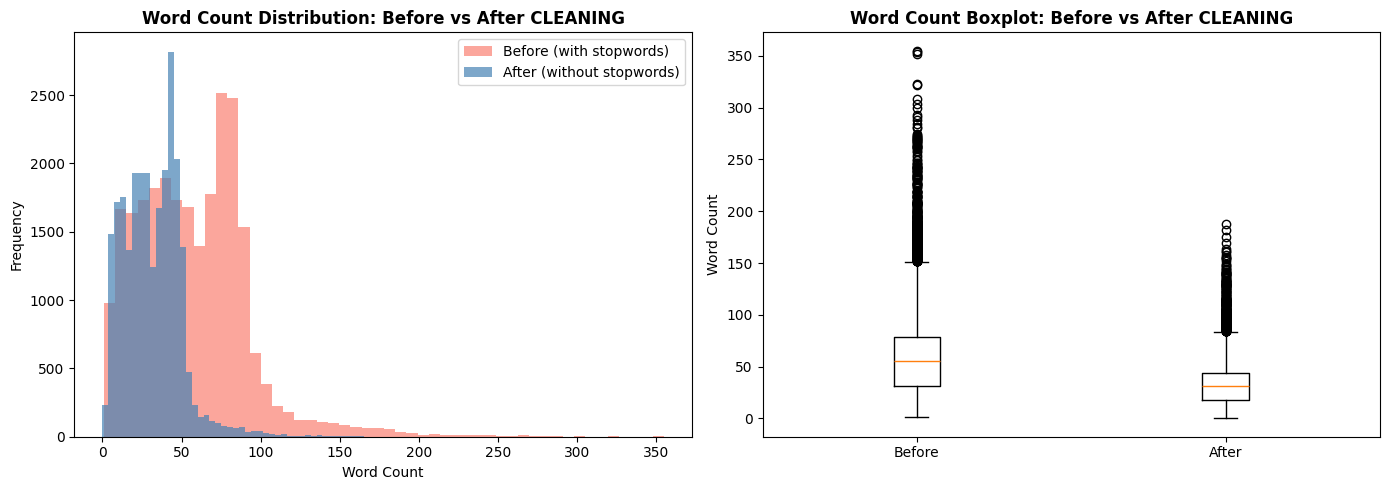


── Sample: Before vs After ──

ORIGINAL:
  Dear Customer Support Team,I am writing to report a significant problem with the centralized account management portal, which currently appears to be offline. This outage is blocking access to account...

AFTER CLEANING + STOPWORD REMOVAL:
  writing report significant problem centralized account management portal currently appears offline outage blocking access account settings leading substantial inconvenience attempted log multiple time...


In [ ]:
# ══════════════════════════════════════════════════════════════
# Stopwords Removal + Impact Visualization
# ══════════════════════════════════════════════════════════════

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
import matplotlib.pyplot as plt

# ─── 1. Before: word counts with stopwords (current state) ───
before_lengths = df_ml['Body_clean_ml'].str.split().str.len()

# ─── 2. Remove stopwords ───
def remove_stopwords(text):
    words = text.split()
    words = [w for w in words if w not in ENGLISH_STOP_WORDS]
    return " ".join(words)

df_ml['Body_clean_ml'] = df_ml['Body_clean_ml'].apply(remove_stopwords)

# ─── 3. After: word counts without stopwords ───
after_lengths = df_ml['Body_clean_ml'].str.split().str.len()

# ─── 4. Print the difference ───
print("=" * 55)
print("  IMPACT OF STOPWORD REMOVAL")
print("=" * 55)
print(f"  {'Metric':<30} {'Before':>8} {'After':>8} {'Change':>10}")
print("  " + "─" * 56)
print(f"  {'Mean word count':<30} {before_lengths.mean():>8.1f} {after_lengths.mean():>8.1f} {after_lengths.mean() - before_lengths.mean():>+10.1f}")
print(f"  {'Median word count':<30} {before_lengths.median():>8.1f} {after_lengths.median():>8.1f} {after_lengths.median() - before_lengths.median():>+10.1f}")
print(f"  {'Total words removed':<30} {'':<8} {'':<8} {(before_lengths.sum() - after_lengths.sum()):>+10,}")

pct_removed = (1 - after_lengths.sum() / before_lengths.sum()) * 100
print(f"  {'% of words removed':<30} {'':<8} {'':<8} {pct_removed:>9.1f}%")
print("=" * 55)

# ─── 5. Visualization ───
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(before_lengths, bins=50, color='salmon', alpha=0.7, label='Before (with stopwords)')
axes[0].hist(after_lengths, bins=50, color='steelblue', alpha=0.7, label='After (without stopwords)')
axes[0].set_title('Word Count Distribution: Before vs After CLEANING', fontweight='bold')
axes[0].set_xlabel('Word Count')
axes[0].set_ylabel('Frequency')
axes[0].legend()

# Boxplot
axes[1].boxplot([before_lengths, after_lengths], labels=['Before', 'After'])
axes[1].set_title('Word Count Boxplot: Before vs After CLEANING', fontweight='bold')
axes[1].set_ylabel('Word Count')

plt.tight_layout()
plt.show()

# ─── 6. Sample to see the difference ───
print("\n── Sample: Before vs After ──\n")
idx = df_ml.index[0]
original = df[df.index == idx]['Body'].values[0]
cleaned = df_ml.loc[idx, 'Body_clean_ml']
print(f"ORIGINAL:\n  {original[:200]}...\n")
print(f"AFTER CLEANING + STOPWORD REMOVAL:\n  {cleaned[:200]}...")

In [ ]:
df_ml.isna().sum()


,0
Body,0
Department,0
Body_clean_ml,0


## قراءة الرسم

---

### إيه اللي بنشوفه؟

الرسم ده بيقارن طول التذاكر قبل وبعد كل عمليات التنظيف مع بعض (حذف الـ HTML والـ placeholders والـ boilerplate والـ stopwords).

**في الـ Histogram (الرسم الشمال):**

الأحمر (Before) كان معظم التذاكر طولها بين 50 و 100 كلمة. الأزرق (After) اتزحلق لليسار وبقى معظمها بين 15 و 50 كلمة. يعني التنظيف شال تقريباً نص الكلمات.

**في الـ Boxplot (الرسم اليمين):**

الـ Median نزل من حوالي 55 كلمة لـ 30 كلمة. الـ Box كله صغر وده معناه إن التذاكر بقت أكتر تجانساً في الطول. الـ Outliers نزلت من 350 كلمة لـ 190 تقريباً.

---

### ده معناه إيه؟

معناه إن حوالي 45% من كلمات كل تذكرة كانت حاجات مش مفيدة للتصنيف: كلمات شائعة زي "the, is, to" وعبارات جاهزة زي "dear customer support team" وعلامات HTML و placeholders. كل ده اتشال ودلوقتي النص اللي فاضل هو اللب: الكلمات اللي فعلاً بتوصف المشكلة وبتساعد الموديل يصنف.

---

### بيساعدني فين؟

**أولاً: في أداء الموديل.**

الموديل دلوقتي بيشوف كلمات مفيدة بس. بدل ما يحاول يلاقي إشارات تصنيف وسط 80 كلمة أغلبها ضوضاء، دلوقتي بيشوف 35 كلمة كلها مهمة. ده المفروض يحسن النتائج.

**ثانياً: في الكتابة.**

الرسم ده بيتحط في فصل الـ Preprocessing كدليل بصري إن التنظيف عمل فرق واضح. بتكتب جنبه:

Preprocessing reduced the average ticket length from approximately 55 words to 30 words, removing around 45% of the content. This reduction primarily eliminated stopwords, boilerplate phrases, HTML tags, and PII placeholders, retaining only the semantically meaningful terms relevant for classification.

**ثالثاً: في المقارنة بين الـ Approach A والـ B.**

ده بيبين إن الطريقة الكلاسيكية محتاجة شغل تنظيف كتير عشان تشتغل كويس. لكن في الـ Fine-Tuning مش هتعمل أي حاجة من ده لأن الـ LLM بيفهم النص كامل بالـ stopwords والـ boilerplate وكل حاجة. وده في حد ذاته نقطة مقارنة مهمة في مشروعك.

In [ ]:
# ══════════════════════════════════════════════════════════════
# Lemmatization: Return each word to its base form
# ══════════════════════════════════════════════════════════════

import nltk
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

def lemmatize_text(text):
    words = text.split()
    words = [lemmatizer.lemmatize(w) for w in words]
    return " ".join(words)

# ─── Before Lemmatization: count vocabulary ───
vocab_before = set(" ".join(df_ml['Body_clean_ml']).split())

# ─── Apply Lemmatization ───
df_ml['Body_clean_ml'] = df_ml['Body_clean_ml'].apply(lemmatize_text)

# ─── After Lemmatization: count vocabulary ───
vocab_after = set(" ".join(df_ml['Body_clean_ml']).split())

# ─── Show Impact ───
print("=" * 55)
print("  IMPACT OF LEMMATIZATION")
print("=" * 55)
print(f"  Vocabulary BEFORE: {len(vocab_before):,} unique words")
print(f"  Vocabulary AFTER:  {len(vocab_after):,} unique words")
print(f"  Words merged:      {len(vocab_before) - len(vocab_after):,} ({(len(vocab_before) - len(vocab_after)) / len(vocab_before) * 100:.1f}%)")
print("=" * 55)

# ─── Show examples of what changed ───
print("\n── Examples of Lemmatized Words ──\n")

examples = [
    ("issues", lemmatizer.lemmatize("issues")),
    ("strategies", lemmatizer.lemmatize("strategies")),
    ("services", lemmatizer.lemmatize("services")),
    ("running", lemmatizer.lemmatize("running", pos='v')),
    ("payments", lemmatizer.lemmatize("payments")),
    ("devices", lemmatizer.lemmatize("devices")),
    ("companies", lemmatizer.lemmatize("companies")),
    ("outages", lemmatizer.lemmatize("outages")),
    ("vulnerabilities", lemmatizer.lemmatize("vulnerabilities")),
    ("integrations", lemmatizer.lemmatize("integrations")),
]

for before, after in examples:
    changed = "→" if before != after else "  (no change)"
    print(f'  {before:<25s} {changed} {after}')

# ─── Show a sample ticket before vs after ───
print("\n── Sample Ticket ──\n")
sample_idx = df_ml.index[5]
print(f"BEFORE lemmatization (first 150 chars):")
# We need to re-derive "before" from earlier steps, so just show current
print(f"  {df_ml.loc[sample_idx, 'Body_clean_ml'][:150]}...")

  IMPACT OF LEMMATIZATION
  Vocabulary BEFORE: 6,495 unique words
  Vocabulary AFTER:  5,692 unique words
  Words merged:      803 (12.4%)

── Examples of Lemmatized Words ──

  issues                    → issue
  strategies                → strategy
  services                  → service
  running                   → run
  payments                  → payment
  devices                   → device
  companies                 → company
  outages                   → outage
  vulnerabilities           → vulnerability
  integrations              → integration

── Sample Ticket ──

BEFORE lemmatization (first 150 chars):
  submitting report regarding multiple service disruption currently interfering project operation client interaction interruption notably reduced effici...


In [ ]:
df_ml.isna().sum()


,0
Body,0
Department,0
Body_clean_ml,0


In [ ]:
# ══════════════════════════════════════════════════════════════
# Impact of Lemmatization on TF-IDF Keywords
# ══════════════════════════════════════════════════════════════

from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd

# ─── 1. Save current (after lemmatization) text ───
after_lemma = df_ml['Body_clean_ml'].copy()

# ─── 2. Quick reverse test: what would it look like WITHOUT lemmatization? ───
# We re-read the original and apply all steps EXCEPT lemmatization
df_test = df[['Body', 'Department']].dropna().copy()
df_test['text'] = df_test['Body'].str.lower()
df_test['text'] = df_test['text'].str.replace(r'<[^>]+>', ' ', regex=True)
df_test['text'] = df_test['text'].str.replace(r'http\S+', ' ', regex=True)
df_test['text'] = df_test['text'].apply(remove_placeholders)
df_test['text'] = df_test['text'].apply(remove_boilerplate)
df_test['text'] = df_test['text'].apply(normalize_text)
df_test['text'] = df_test['text'].apply(remove_stopwords)

before_lemma = df_test['text']

# ─── 3. TF-IDF on both ───
vec_before = TfidfVectorizer(max_features=5000, ngram_range=(1,2))
vec_after  = TfidfVectorizer(max_features=5000, ngram_range=(1,2))

vec_before.fit(before_lemma)
vec_after.fit(after_lemma)

vocab_before = set(vec_before.get_feature_names_out())
vocab_after  = set(vec_after.get_feature_names_out())

# ─── 4. Vocabulary comparison ───
print("=" * 55)
print("  VOCABULARY COMPARISON")
print("=" * 55)
print(f"  TF-IDF features BEFORE lemmatization: {len(vocab_before):,}")
print(f"  TF-IDF features AFTER lemmatization:  {len(vocab_after):,}")
print(f"  Reduction: {len(vocab_before) - len(vocab_after):,} features")
print("=" * 55)

# ─── 5. Show words that got merged ───
disappeared = vocab_before - vocab_after
appeared = vocab_after - vocab_before

print(f"\n── Words that DISAPPEARED (merged into base form): {len(disappeared)} ──\n")
sample_gone = sorted(list(disappeared))[:20]
for w in sample_gone:
    print(f"  ✗ {w}")

print(f"\n── Base forms that APPEARED (result of merging): {len(appeared)} ──\n")
sample_new = sorted(list(appeared))[:20]
for w in sample_new:
    print(f"  ✓ {w}")

# ─── 6. Top keywords comparison per department ───
print("\n" + "=" * 55)
print("  TOP KEYWORDS: BEFORE vs AFTER LEMMATIZATION")
print("=" * 55)

X_b = vec_before.transform(before_lemma)
X_a = vec_after.transform(after_lemma)

tfidf_b = pd.DataFrame(X_b.toarray(), columns=vec_before.get_feature_names_out())
tfidf_a = pd.DataFrame(X_a.toarray(), columns=vec_after.get_feature_names_out())

tfidf_b['Department'] = df_test['Department'].values
tfidf_a['Department'] = df_ml['Department'].values

for dept in ['Billing and Payments', 'Technical Support', 'IT Support']:
    top_b = tfidf_b[tfidf_b['Department'] == dept].drop(columns=['Department']).mean().sort_values(ascending=False).head(8)
    top_a = tfidf_a[tfidf_a['Department'] == dept].drop(columns=['Department']).mean().sort_values(ascending=False).head(8)

    print(f"\n┌─── {dept} ───")
    print(f"│")
    print(f"│  {'BEFORE lemmatization':<35s} {'AFTER lemmatization'}")
    print(f"│  {'─' * 35} {'─' * 35}")

    for i in range(8):
        bw = f"{top_b.index[i]:<20s} {top_b.values[i]:.4f}"
        aw = f"{top_a.index[i]:<20s} {top_a.values[i]:.4f}"
        print(f"│  {bw:<35s} {aw}")
    print("└" + "─" * 72)

  VOCABULARY COMPARISON
  TF-IDF features BEFORE lemmatization: 5,000
  TF-IDF features AFTER lemmatization:  5,000
  Reduction: 0 features

── Words that DISAPPEARED (merged into base form): 1301 ──

  ✗ access attempts
  ✗ access controls
  ✗ access credentials
  ✗ access issues
  ✗ access logs
  ✗ access problems
  ✗ access restrictions
  ✗ account details
  ✗ account settings
  ✗ accounts
  ✗ achieve goals
  ✗ actions
  ✗ actions need
  ✗ actions taken
  ✗ activities
  ✗ ad placements
  ✗ additional actions
  ✗ additional details
  ✗ additional fees
  ✗ additional measures

── Base forms that APPEARED (result of merging): 1301 ──

  ✓ acc
  ✓ acc num
  ✓ access alert
  ✓ access credential
  ✓ access issue
  ✓ access log
  ✓ access problem
  ✓ access restriction
  ✓ account acc
  ✓ account detail
  ✓ account setting
  ✓ action need
  ✓ action required
  ✓ action taken
  ✓ ad placement
  ✓ adapter
  ✓ additional action
  ✓ additional detail
  ✓ additional fee
  ✓ additional measure



In [ ]:
df_ml.isna().sum()


,0
Body,0
Department,0
Body_clean_ml,0


In [ ]:
# ══════════════════════════════════════════════════════════════
# Clean Dataset Before Saving
# ══════════════════════════════════════════════════════════════

import pandas as pd

# Remove missing values
df_ml = df_ml.dropna(subset=['Body_clean_ml'])

# Remove empty strings
df_ml = df_ml[df_ml['Body_clean_ml'].astype(str).str.strip() != '']

# Reset index
df_ml = df_ml.reset_index(drop=True)

print("Final cleaned shape:", df_ml.shape)

# Check missing values
print("\nMissing values:\n")
print(df_ml.isna().sum())

# Save cleaned dataset
save_path = '/content/drive/MyDrive/df_ml_cleaned.csv'

df_ml.to_csv(save_path, index=False)

print(f"\nCleaned data saved to: {save_path}")

Final cleaned shape: (25220, 3)

Missing values:

Body             0
Department       0
Body_clean_ml    0
dtype: int64

Cleaned data saved to: /content/drive/MyDrive/df_ml_cleaned.csv


In [ ]:
# ══════════════════════════════════════════════════════════════
# Load Cleaned Dataset from Google Drive
# ══════════════════════════════════════════════════════════════

import pandas as pd
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')
# Path to cleaned dataset
load_path = '/content/drive/MyDrive/df_ml_cleaned.csv'

# Prevent empty strings from becoming NaN
df_ml = pd.read_csv(load_path, keep_default_na=False)

# Final safety cleaning
df_ml = df_ml[df_ml['Body_clean_ml'].astype(str).str.strip() != '']

# Reset index
df_ml = df_ml.reset_index(drop=True)

# Features and labels
X_text = df_ml['Body_clean_ml']
y = df_ml['Department']

# Dataset information
print("Number of samples:", len(X_text))
print("Number of classes:", y.nunique())

print("\nClass Distribution:\n")
print(y.value_counts())

print("\nMissing values after loading:\n")
print(df_ml.isna().sum())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Number of samples: 25220
Number of classes: 10

Class Distribution:

Department
Technical Support                  7343
Product Support                    4670
Customer Service                   3789
IT Support                         3009
Billing and Payments               2563
Returns and Exchanges              1243
Service Outages and Maintenance    1000
Sales and Pre-Sales                 768
Human Resources                     477
General Inquiry                     358
Name: count, dtype: int64

Missing values after loading:

Body             0
Department       0
Body_clean_ml    0
dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

# === FIXED: 80/10/10 split instead of 80/20 ===
# Added validation set for hyperparameter tuning

# Step 1: 80% train, 20% temp
X_train_text, X_temp_text, y_train, y_temp = train_test_split(
    X_text, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Step 2: Split temp into 50/50 → 10% val + 10% test
X_val_text, X_test_text, y_val, y_test = train_test_split(
    X_temp_text, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

print(f"Train size: {len(X_train_text)} ({len(X_train_text)/len(X_text)*100:.0f}%)")
print(f"Val size:   {len(X_val_text)} ({len(X_val_text)/len(X_text)*100:.0f}%)")
print(f"Test size:  {len(X_test_text)} ({len(X_test_text)/len(X_text)*100:.0f}%)")
print(f"\nClass distribution in test set:")
print(y_test.value_counts())

Train size: 20176 (80%)
Val size:   2522 (10%)
Test size:  2522 (10%)

Class distribution in test set:
Department
Technical Support                  734
Product Support                    467
Customer Service                   379
IT Support                         301
Billing and Payments               256
Returns and Exchanges              124
Service Outages and Maintenance    100
Sales and Pre-Sales                 77
Human Resources                     48
General Inquiry                     36
Name: count, dtype: int64


that counts the unique words and we will use it in modelling

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
temp_vec = CountVectorizer(stop_words='english')
temp_vec.fit(X_train_text)
vocab_size = len(temp_vec.vocabulary_)
print(f'Vocab size: {vocab_size}')

Vocab size: 5402


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer


tfidf_vectorizer = TfidfVectorizer(
    max_features=10000, #because we have n grams
    ngram_range=(1, 2),
    min_df=2,              # ignore words appearing in only 1 document
    max_df=0.95            # ignore words appearing in >95% of documents
)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_text)
X_val_tfidf   = tfidf_vectorizer.transform(X_val_text)
X_test_tfidf  = tfidf_vectorizer.transform(X_test_text)


print("X_train shape:", X_train_tfidf.shape)
print("X_test shape:", X_test_tfidf.shape)
print("X_val_tfidf shape:", X_val_tfidf.shape)
print(f"\nVocabulary size: {len(tfidf_vectorizer.vocabulary_)}")

X_train shape: (20176, 10000)
X_test shape: (2522, 10000)
X_val_tfidf shape: (2522, 10000)

Vocabulary size: 10000


navie bayes


# Hyperparameter tuning is performed using GridSearchCV with cross-validation.
# The search is conducted on the training set only to avoid data leakage.
# The main parameter tuned is the regularization strength (C),
# along with solver selection.
# Macro F1-score is used as the evaluation metric due to class imbalance.


Best parameters : {'C': 10, 'penalty': 'l2', 'solver': 'liblinear'}
Best CV F1-macro: 0.5080
GridSearch time : 4311.4s (71.86 min)

  LOGISTIC REGRESSION — FINAL RESULTS
  Val  Accuracy : 0.5400
  Val  F1-macro : 0.5316
  Test Accuracy : 0.5559
  Test F1-macro : 0.5651
  Inference     : 0.001 ms/sample

Classification Report (Test):

                                 precision    recall  f1-score   support

           Billing and Payments       0.76      0.84      0.80       256
               Customer Service       0.49      0.48      0.49       379
                General Inquiry       0.53      0.47      0.50        36
                Human Resources       0.65      0.65      0.65        48
                     IT Support       0.45      0.46      0.46       301
                Product Support       0.50      0.48      0.49       467
          Returns and Exchanges       0.40      0.48      0.44       124
            Sales and Pre-Sales       0.47      0.62      0.54        77
Servi

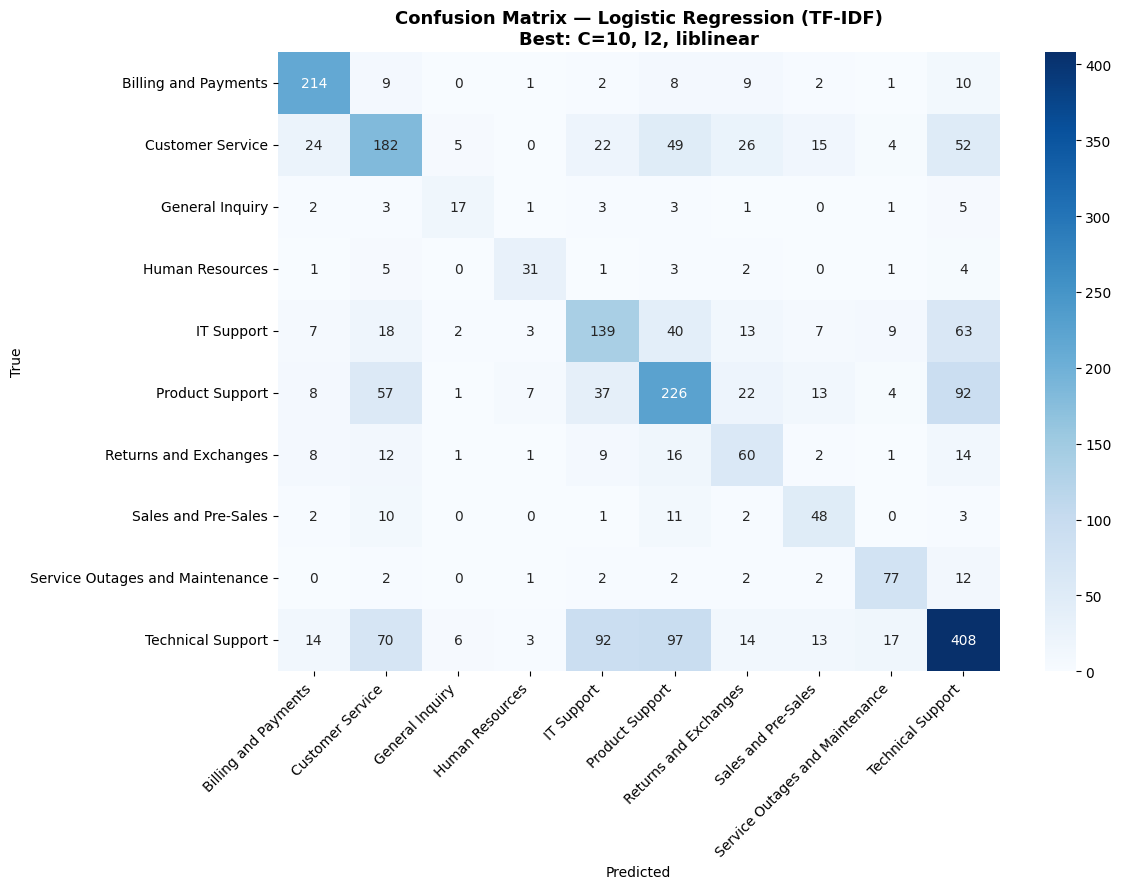

In [ ]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (accuracy_score, f1_score,
                             classification_report, confusion_matrix)
import seaborn as sns
import matplotlib.pyplot as plt
# ───  Hyperparameter Search (on train only, 3-fold CV) ───
# Grid covers compatible solver/penalty combinations:
#   lbfgs  → L2 only (multinomial loss, good for dense problems)
#   liblinear → L1 or L2 (OvR for multiclass, fast on sparse)
#   saga   → L1 or L2 (multinomial loss, stochastic, slower)
# C: inverse regularisation strength; larger C = less penalty
# Scoring: macro F1 — equal weight to all 10 classes

lr = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

param_grid = [
    {'C': [0.01, 0.1, 1, 3, 10], 'solver': ['lbfgs'],     'penalty': ['l2']      },
    {'C': [0.01, 0.1, 1, 3, 10], 'solver': ['liblinear'], 'penalty': ['l1', 'l2']},
    {'C': [0.01, 0.1, 1, 3, 10], 'solver': ['saga'],      'penalty': ['l1', 'l2']},
]

grid = GridSearchCV(
    estimator=lr,
    param_grid=param_grid,
    cv=3,
    scoring='f1_macro',
    n_jobs=-1
)

# ─── 3. Training with timing ───
train_start = time.time()
grid.fit(X_train_tfidf, y_train)
train_end = time.time()
tuning_time = train_end - train_start

print(f"\nBest parameters : {grid.best_params_}")
print(f"Best CV F1-macro: {grid.best_score_:.4f}")
print(f"GridSearch time : {tuning_time:.1f}s ({tuning_time/60:.2f} min)")

# ─── 4. Final model with best params ───
best_lr = grid.best_estimator_

# ─── 5. Evaluation with timing ───
# Validation
val_start = time.time()
val_pred  = best_lr.predict(X_val_tfidf)
val_end   = time.time()
val_time  = (val_end - val_start) / len(X_val_text) * 1000  # ms/sample

# Test (consulted once — final evaluation only)
test_start = time.time()
test_pred  = best_lr.predict(X_test_tfidf)
test_end   = time.time()
test_time  = (test_end - test_start) / len(X_test_text) * 1000  # ms/sample

# ─── 6. Results ───
print("\n" + "="*55)
print("  LOGISTIC REGRESSION — FINAL RESULTS")
print("="*55)
print(f"  Val  Accuracy : {accuracy_score(y_val, val_pred):.4f}")
print(f"  Val  F1-macro : {f1_score(y_val, val_pred, average='macro'):.4f}")
print(f"  Test Accuracy : {accuracy_score(y_test, test_pred):.4f}")
print(f"  Test F1-macro : {f1_score(y_test, test_pred, average='macro'):.4f}")
print(f"  Inference     : {test_time:.3f} ms/sample")
print("="*55)

print("\nClassification Report (Test):\n")
print(classification_report(y_test, test_pred))

# ─── 7. Confusion Matrix ───
cm = confusion_matrix(y_test, test_pred, labels=best_lr.classes_)
plt.figure(figsize=(12, 9))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=best_lr.classes_,
            yticklabels=best_lr.classes_)
plt.title(f"Confusion Matrix — Logistic Regression (TF-IDF)\n"
          f"Best: C={grid.best_params_['C']}, "
          f"{grid.best_params_['penalty']}, {grid.best_params_['solver']}",
          fontsize=13, fontweight='bold')
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('lr_confusion_matrix.png', dpi=200, bbox_inches='tight')
plt.show()

Training time: 7.63s

Validation Accuracy : 0.5400
Validation F1-macro : 0.5316

Test Accuracy       : 0.5559
Test F1-macro       : 0.5651
Inference latency   : 0.001 ms/sample

Classification Report (Test):

                                 precision    recall  f1-score   support

           Billing and Payments       0.76      0.84      0.80       256
               Customer Service       0.49      0.48      0.49       379
                General Inquiry       0.53      0.47      0.50        36
                Human Resources       0.65      0.65      0.65        48
                     IT Support       0.45      0.46      0.46       301
                Product Support       0.50      0.48      0.49       467
          Returns and Exchanges       0.40      0.48      0.44       124
            Sales and Pre-Sales       0.47      0.62      0.54        77
Service Outages and Maintenance       0.67      0.77      0.72       100
              Technical Support       0.62      0.56      0.

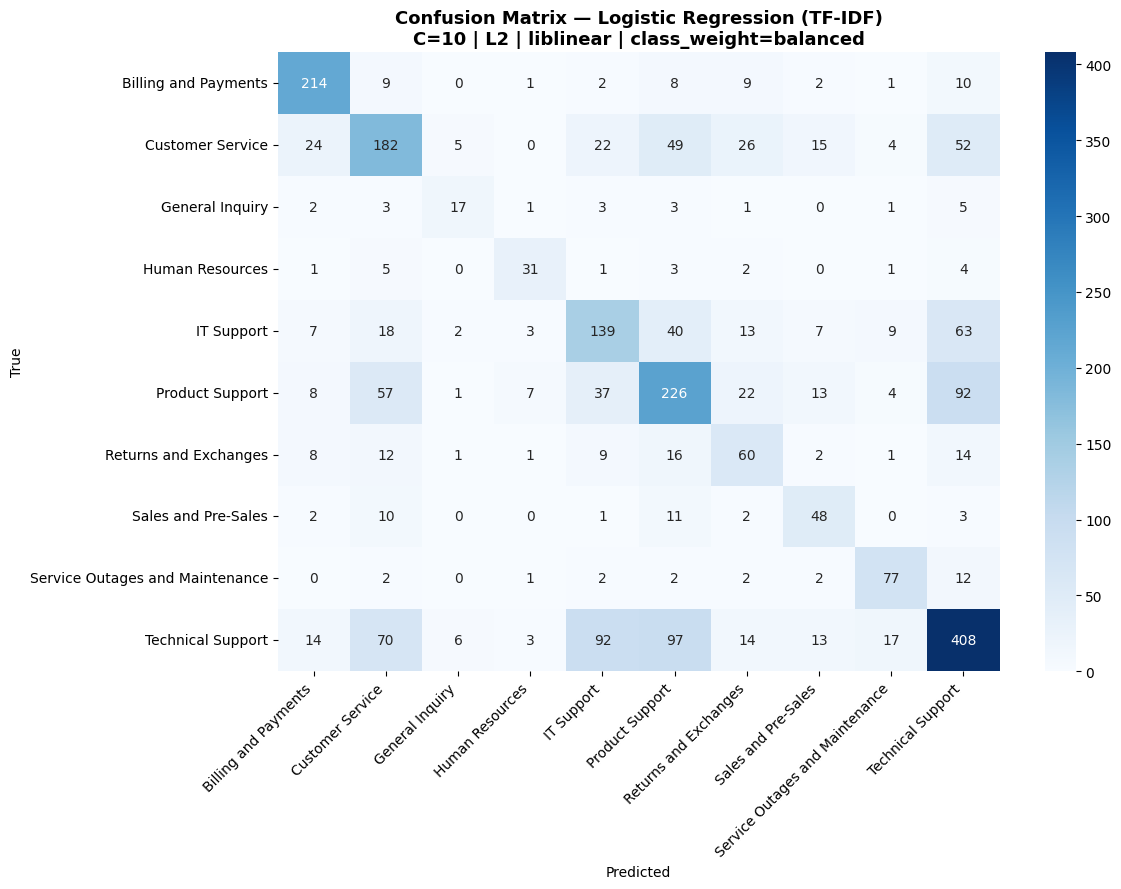

In [ ]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score,
                             classification_report, confusion_matrix)
import seaborn as sns
import matplotlib.pyplot as plt

# ══════════════════════════════════════════════════════════════
# LOGISTIC REGRESSION — Final Model (Best params from GridSearch)
# TF-IDF only — no metadata features
# ══════════════════════════════════════════════════════════════

# ─── 1. Define final model ───
# Best params from GridSearchCV: C=10, l2, liblinear
# C=10: low regularisation → model fits the high-dim TF-IDF space
# liblinear: coordinate-descent solver, efficient on sparse matrices
# class_weight='balanced': compensates for 21:1 class imbalance

best_lr = LogisticRegression(
    C=10,
    penalty='l2',
    solver='liblinear',
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

# ─── 2. Train on TRAIN data (with timing) ───
train_start = time.time()
best_lr.fit(X_train_tfidf, y_train)
train_end   = time.time()
train_time  = train_end - train_start

print(f"Training time: {train_time:.2f}s")

# ─── 3. Validation evaluation ───
val_pred = best_lr.predict(X_val_tfidf)

print(f"\nValidation Accuracy : {accuracy_score(y_val, val_pred):.4f}")
print(f"Validation F1-macro : {f1_score(y_val, val_pred, average='macro'):.4f}")

# ─── 4. Test evaluation (consulted once — final only) ───
test_start = time.time()
test_pred  = best_lr.predict(X_test_tfidf)
test_end   = time.time()
test_time  = (test_end - test_start) / len(X_test_text) * 1000  # ms/sample

print(f"\nTest Accuracy       : {accuracy_score(y_test, test_pred):.4f}")
print(f"Test F1-macro       : {f1_score(y_test, test_pred, average='macro'):.4f}")
print(f"Inference latency   : {test_time:.3f} ms/sample")

print("\nClassification Report (Test):\n")
print(classification_report(y_test, test_pred))

# ─── 5. Confusion Matrix ───
cm     = confusion_matrix(y_test, test_pred, labels=best_lr.classes_)
plt.figure(figsize=(12, 9))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=best_lr.classes_,
            yticklabels=best_lr.classes_)
plt.title("Confusion Matrix — Logistic Regression (TF-IDF)\n"
          "C=10 | L2 | liblinear | class_weight=balanced",
          fontsize=13, fontweight='bold')
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('lr_confusion_matrix.png', dpi=200, bbox_inches='tight')
plt.show()

bow and naives bayes

  MNB BASELINE (BoW, default params)
  Training time  : 0.05s
  Val  Accuracy  : 0.3874
  Val  F1-macro  : 0.3191
  Test Accuracy  : 0.3977
  Test F1-macro  : 0.3469

Classification Report (Test):

                                 precision    recall  f1-score   support

           Billing and Payments       0.82      0.70      0.75       256
               Customer Service       0.27      0.40      0.32       379
                General Inquiry       0.28      0.19      0.23        36
                Human Resources       0.59      0.21      0.31        48
                     IT Support       0.29      0.09      0.13       301
                Product Support       0.38      0.23      0.28       467
          Returns and Exchanges       0.25      0.12      0.16       124
            Sales and Pre-Sales       0.17      0.32      0.22        77
Service Outages and Maintenance       0.54      0.60      0.57       100
              Technical Support       0.42      0.58      0.48       73

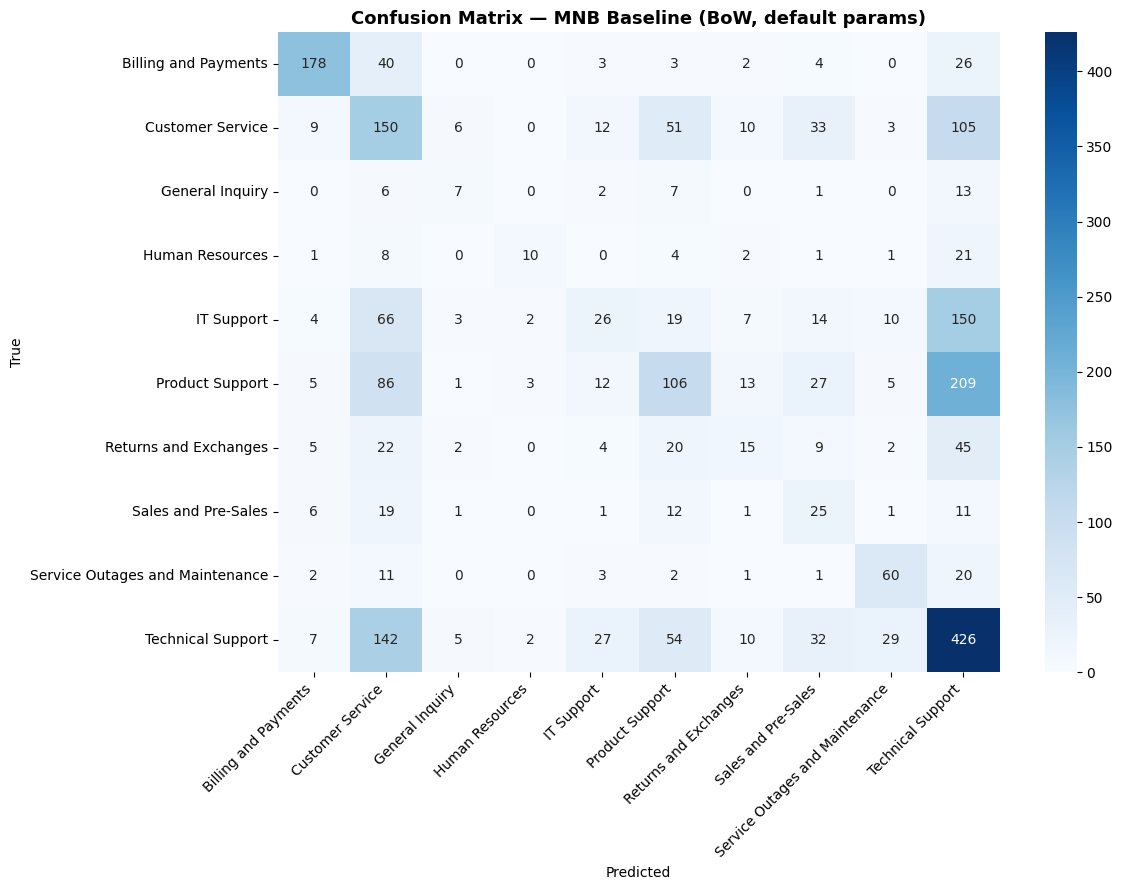

In [ ]:
import time
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import (accuracy_score, f1_score,
                             classification_report, confusion_matrix)
import seaborn as sns
import matplotlib.pyplot as plt

# ── Baseline: MNB + BoW (default parameters, no tuning) ──
# Serves as a lower-bound reference for the tuned TF-IDF model.
# vocab_size = full unigram vocabulary after preprocessing (5,402 tokens)

bow_vectorizer = CountVectorizer(
    max_features=vocab_size,
    min_df=2,
    max_df=0.95
)

X_train_bow = bow_vectorizer.fit_transform(X_train_text)
X_val_bow   = bow_vectorizer.transform(X_val_text)
X_test_bow  = bow_vectorizer.transform(X_test_text)

train_start = time.time()
nb_baseline = MultinomialNB()           # alpha=1.0, fit_prior=True (defaults)
nb_baseline.fit(X_train_bow, y_train)
train_end   = time.time()

val_pred  = nb_baseline.predict(X_val_bow)
test_pred = nb_baseline.predict(X_test_bow)

print("="*50)
print("  MNB BASELINE (BoW, default params)")
print("="*50)
print(f"  Training time  : {train_end - train_start:.2f}s")
print(f"  Val  Accuracy  : {accuracy_score(y_val, val_pred):.4f}")
print(f"  Val  F1-macro  : {f1_score(y_val, val_pred, average='macro'):.4f}")
print(f"  Test Accuracy  : {accuracy_score(y_test, test_pred):.4f}")
print(f"  Test F1-macro  : {f1_score(y_test, test_pred, average='macro'):.4f}")
print("="*50)

print("\nClassification Report (Test):\n")
print(classification_report(y_test, test_pred))

cm = confusion_matrix(y_test, test_pred, labels=nb_baseline.classes_)
plt.figure(figsize=(12, 9))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=nb_baseline.classes_,
            yticklabels=nb_baseline.classes_)
plt.title("Confusion Matrix — MNB Baseline (BoW, default params)",
          fontsize=13, fontweight='bold')
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('nb_baseline_confusion_matrix.png', dpi=200, bbox_inches='tight')
plt.show()

In [ ]:
print(f"Final BoW vocab (after min_df=2, max_df=0.95): {len(bow_vectorizer.vocabulary_)}")

Final BoW vocab (after min_df=2, max_df=0.95): 4300


GridSearch time : 7.3s (0.12 min)
Best parameters : {'alpha': 0.01, 'fit_prior': False}
Best CV F1-macro: 0.4214

── All combinations (sorted by CV F1-macro) ──

 alpha  fit_prior  Mean F1-Macro      Std  Rank
  0.01      False       0.421371 0.010527     1
  0.01       True       0.415089 0.006967     2
  0.10      False       0.394104 0.004897     3
  0.10       True       0.368591 0.007929     4
  0.50      False       0.345436 0.004175     5
  1.00      False       0.280991 0.000273     6
  0.50       True       0.242577 0.002071     7
  1.00       True       0.198095 0.002862     8
  5.00      False       0.183271 0.002277     9
 10.00      False       0.163890 0.002568    10
  5.00       True       0.140837 0.001781    11
 10.00       True       0.103923 0.003397    12

  MULTINOMIAL NAIVE BAYES — FINAL RESULTS
  Best alpha     : 0.01
  Best fit_prior : False
  Val  Accuracy  : 0.4469
  Val  F1-macro  : 0.4260
  Test Accuracy  : 0.4441
  Test F1-macro  : 0.4376
  Inference      :

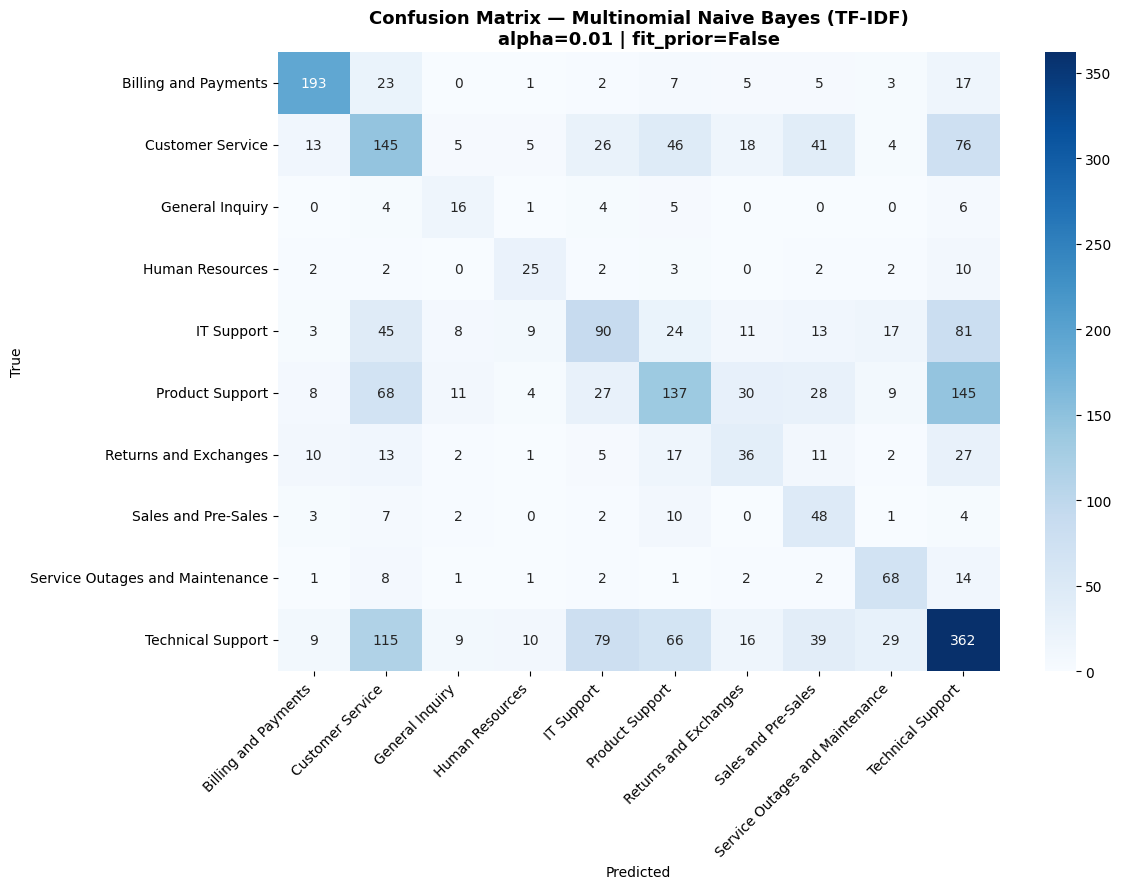

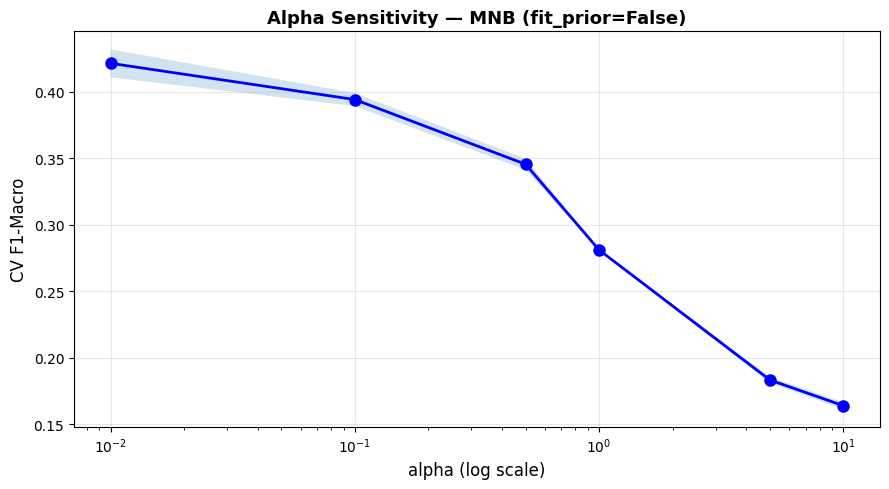

In [ ]:
import time
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (accuracy_score, f1_score,
                             classification_report, confusion_matrix)
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# ══════════════════════════════════════════════════════════════
# MULTINOMIAL NAIVE BAYES — TF-IDF only (no metadata features)
# References:
#   Manning et al. (2008), Introduction to Information Retrieval,
#   Cambridge University Press, pp. 234–265.
#   McCallum & Nigam (1998), A Comparison of Event Models for
#   Naive Bayes Text Classification, AAAI Workshop.
# ══════════════════════════════════════════════════════════════

# ─── 1. Hyperparameter Grid ───
# MNB has exactly three tunable parameters:
#
#   alpha (Laplace/Lidstone smoothing):
#     Controls the additive constant added to all term counts before
#     normalisation. Small values (e.g. 0.01) preserve the influence
#     of rare, discriminative terms; large values (e.g. 10.0) flatten
#     term distributions toward uniformity, effectively ignoring rare
#     words. Manning et al. (2008) recommend alpha=1.0 as a principled
#     default; the optimal value is corpus-dependent.
#
#   fit_prior:
#     If True, the class prior P(c) is estimated from training-set
#     class frequencies. Under severe class imbalance (21:1 ratio in
#     this corpus), a learned prior amplifies the majority class and
#     may suppress minority-class recall. Setting fit_prior=False
#     enforces a uniform prior, delegating all discriminative work
#     to the likelihood term.
#
#   class_prior:
#     An alternative to fit_prior — allows manual specification of
#     class weights. None defers to fit_prior; a uniform vector
#     [1/10]*10 replicates fit_prior=False analytically.
#     Kept as None here to avoid redundancy with fit_prior=False.

param_grid = {
    'alpha':     [0.01, 0.1, 0.5, 1.0, 5.0, 10.0],
    'fit_prior': [True, False]
}

# ─── 2. GridSearchCV (on train only — 3-fold, macro F1) ───
# cv=3 chosen for consistency with LR and RF experiments.
# scoring=f1_macro: assigns equal weight to all 10 classes,
# preventing majority-class dominance from inflating the score.

grid_search = GridSearchCV(
    estimator=MultinomialNB(),
    param_grid=param_grid,
    cv=3,
    scoring='f1_macro',
    n_jobs=-1,
    return_train_score=True
)

train_start = time.time()
grid_search.fit(X_train_tfidf, y_train)
train_end   = time.time()
tuning_time = train_end - train_start

print(f"GridSearch time : {tuning_time:.1f}s ({tuning_time/60:.2f} min)")
print(f"Best parameters : {grid_search.best_params_}")
print(f"Best CV F1-macro: {grid_search.best_score_:.4f}")

# ─── 3. All combinations (sorted) ───
results_df = pd.DataFrame(grid_search.cv_results_)
results_df = results_df[[
    'param_alpha', 'param_fit_prior',
    'mean_test_score', 'std_test_score', 'rank_test_score'
]].sort_values('rank_test_score')
results_df.columns = ['alpha', 'fit_prior', 'Mean F1-Macro', 'Std', 'Rank']

print("\n── All combinations (sorted by CV F1-macro) ──\n")
print(results_df.to_string(index=False))

# ─── 4. Evaluate best model ───
best_nb = grid_search.best_estimator_

val_pred = best_nb.predict(X_val_tfidf)

val_start  = time.time()
test_pred  = best_nb.predict(X_test_tfidf)
test_end   = time.time()
test_time  = (test_end - val_start) / len(X_test_text) * 1000  # ms/sample

print("\n" + "="*55)
print("  MULTINOMIAL NAIVE BAYES — FINAL RESULTS")
print("="*55)
print(f"  Best alpha     : {grid_search.best_params_['alpha']}")
print(f"  Best fit_prior : {grid_search.best_params_['fit_prior']}")
print(f"  Val  Accuracy  : {accuracy_score(y_val, val_pred):.4f}")
print(f"  Val  F1-macro  : {f1_score(y_val, val_pred, average='macro'):.4f}")
print(f"  Test Accuracy  : {accuracy_score(y_test, test_pred):.4f}")
print(f"  Test F1-macro  : {f1_score(y_test, test_pred, average='macro'):.4f}")
print(f"  Inference      : {test_time:.3f} ms/sample")
print("="*55)

print("\nClassification Report (Test):\n")
print(classification_report(y_test, test_pred))

# ─── 5. Confusion Matrix ───
cm     = confusion_matrix(y_test, test_pred, labels=best_nb.classes_)
plt.figure(figsize=(12, 9))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=best_nb.classes_,
            yticklabels=best_nb.classes_)
plt.title(
    f"Confusion Matrix — Multinomial Naive Bayes (TF-IDF)\n"
    f"alpha={grid_search.best_params_['alpha']} | "
    f"fit_prior={grid_search.best_params_['fit_prior']}",
    fontsize=13, fontweight='bold'
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('nb_confusion_matrix.png', dpi=200, bbox_inches='tight')
plt.show()

# ─── 6. Alpha sensitivity plot ───
best_prior = grid_search.best_params_['fit_prior']
alpha_df   = results_df[results_df['fit_prior'] == best_prior].copy()

plt.figure(figsize=(9, 5))
plt.plot(alpha_df['alpha'], alpha_df['Mean F1-Macro'],
         'bo-', linewidth=2, markersize=8)
plt.fill_between(
    alpha_df['alpha'],
    alpha_df['Mean F1-Macro'] - alpha_df['Std'],
    alpha_df['Mean F1-Macro'] + alpha_df['Std'],
    alpha=0.2
)
plt.xscale('log')
plt.xlabel('alpha (log scale)', fontsize=12)
plt.ylabel('CV F1-Macro', fontsize=12)
plt.title(f'Alpha Sensitivity — MNB (fit_prior={best_prior})',
          fontsize=13, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('nb_alpha_sensitivity.png', dpi=200, bbox_inches='tight')
plt.show()

In [ ]:
pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 21.2 MB/s eta 0:00:00


In [ ]:
# ══════════════════════════════════════════════════════════════
# PART 1: Word2Vec Representation
# ══════════════════════════════════════════════════════════════

import numpy as np
import pandas as pd
from gensim.models import Word2Vec

print("=" * 60)
print("  PART 1: Training Word2Vec Model")
print("=" * 60)

# 1. Tokenization
train_tokens = X_train_text.apply(str.split).tolist()
val_tokens   = X_val_text.apply(str.split).tolist()
test_tokens  = X_test_text.apply(str.split).tolist()

print(f"Sample tokenized ticket: {train_tokens[0][:10]}...")

# 2. Train Word2Vec only on training data
w2v_model = Word2Vec(
    sentences=train_tokens,
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,
    workers=4,
    seed=42,
    epochs=10
)

print(f"Word2Vec vocabulary size: {len(w2v_model.wv)}")
print(f"Vector size per word: {w2v_model.wv.vector_size}")

# 3. Document vector function
def document_vector(tokens, model):
    vectors = [model.wv[word] for word in tokens if word in model.wv]

    if len(vectors) == 0:
        return np.zeros(model.wv.vector_size)

    return np.mean(vectors, axis=0)

# 4. Convert datasets into Word2Vec document vectors
X_train_w2v = np.array([document_vector(doc, w2v_model) for doc in train_tokens])
X_val_w2v   = np.array([document_vector(doc, w2v_model) for doc in val_tokens])
X_test_w2v  = np.array([document_vector(doc, w2v_model) for doc in test_tokens])

print(f"X_train_w2v shape: {X_train_w2v.shape}")
print(f"X_val_w2v shape:   {X_val_w2v.shape}")
print(f"X_test_w2v shape:  {X_test_w2v.shape}")

  PART 1: Training Word2Vec Model
Sample tokenized ticket: ['marketing', 'firm', 'facing', 'difficulty', 'uniform', 'brand', 'messaging', 'various', 'digital', 'channel']...
Word2Vec vocabulary size: 4334
Vector size per word: 100
X_train_w2v shape: (20176, 100)
X_val_w2v shape:   (2522, 100)
X_test_w2v shape:  (2522, 100)


In [ ]:
# ══════════════════════════════════════════════════════════════
# PART 2: Random Forest Hyperparameter Tuning + Training Time
# ══════════════════════════════════════════════════════════════

import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 60)
print("  PART 2: Random Forest Hyperparameter Tuning")
print("=" * 60)

# 1. Parameter search space
param_distributions = {
    'n_estimators': [100, 200, 300],
    'max_depth': [30, 50, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2'],
    'class_weight': ['balanced', 'balanced_subsample']
}

n_iter = 30

rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_distributions,
    n_iter=n_iter,
    cv=3,
    scoring='f1_macro',
    verbose=1,
    n_jobs=-1,
    random_state=42,
    return_train_score=True
)

# 2. Hyperparameter tuning time
tuning_start_time = time.time()

random_search.fit(X_train_w2v, y_train)

tuning_end_time = time.time()
tuning_duration = tuning_end_time - tuning_start_time

print("\n" + "=" * 60)
print("  BEST PARAMETERS FOUND")
print("=" * 60)

for param, value in random_search.best_params_.items():
    print(f"{param:<25s} {value}")

print(f"\nBest CV F1-Macro: {random_search.best_score_:.4f}")

print("\n" + "=" * 60)
print("  HYPERPARAMETER TUNING TIME")
print("=" * 60)
print(f"Start time: {time.ctime(tuning_start_time)}")
print(f"End time:   {time.ctime(tuning_end_time)}")
print(f"Duration:   {tuning_duration / 60:.2f} minutes")

  PART 2: Random Forest Hyperparameter Tuning
Fitting 3 folds for each of 30 candidates, totalling 90 fits


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



  BEST PARAMETERS FOUND
n_estimators              300
min_samples_split         10
min_samples_leaf          2
max_features              sqrt
max_depth                 30
class_weight              balanced_subsample

Best CV F1-Macro: 0.4839

  HYPERPARAMETER TUNING TIME
Start time: Fri May  1 16:57:20 2026
End time:   Fri May  1 17:59:43 2026
Duration:   62.38 minutes


In [ ]:
# ══════════════════════════════════════════════════════════════
# Train Final Random Forest using Best Hyperparameters
# ══════════════════════════════════════════════════════════════
from sklearn.ensemble import RandomForestClassifier

best_params = {
    "n_estimators": 300,
    "min_samples_split": 10,
    "min_samples_leaf": 2,
    "max_features": "sqrt",
    "max_depth": 30,
    "class_weight": "balanced_subsample",
}

final_rf = RandomForestClassifier(
    **best_params,
    random_state=42,
    n_jobs=-1
)

actual_train_start = time.time()

final_rf.fit(X_train_w2v, y_train)

actual_train_end = time.time()
actual_train_duration = actual_train_end - actual_train_start

print("\n" + "=" * 60)
print("  FINAL MODEL ACTUAL TRAINING TIME")
print("=" * 60)
print(f"Training start: {time.ctime(actual_train_start)}")
print(f"Training end:   {time.ctime(actual_train_end)}")
print(f"Training time:  {actual_train_duration / 60:.2f} minutes")


  FINAL MODEL ACTUAL TRAINING TIME
Training start: Sat May 30 15:37:11 2026
Training end:   Sat May 30 15:39:12 2026
Training time:  2.01 minutes



  FINAL RESULTS: Word2Vec + Random Forest
Validation Accuracy : 0.5678
Validation F1-macro : 0.5474
Test Accuracy       : 0.5781
Test F1-macro       : 0.5526

Classification Report - Test Set:

                                 precision    recall  f1-score   support

           Billing and Payments       0.84      0.80      0.82       256
               Customer Service       0.45      0.59      0.51       379
                General Inquiry       0.79      0.31      0.44        36
                Human Resources       0.86      0.40      0.54        48
                     IT Support       0.76      0.37      0.49       301
                Product Support       0.57      0.44      0.50       467
          Returns and Exchanges       0.71      0.27      0.40       124
            Sales and Pre-Sales       0.75      0.39      0.51        77
Service Outages and Maintenance       0.81      0.61      0.70       100
              Technical Support       0.52      0.76      0.62       734



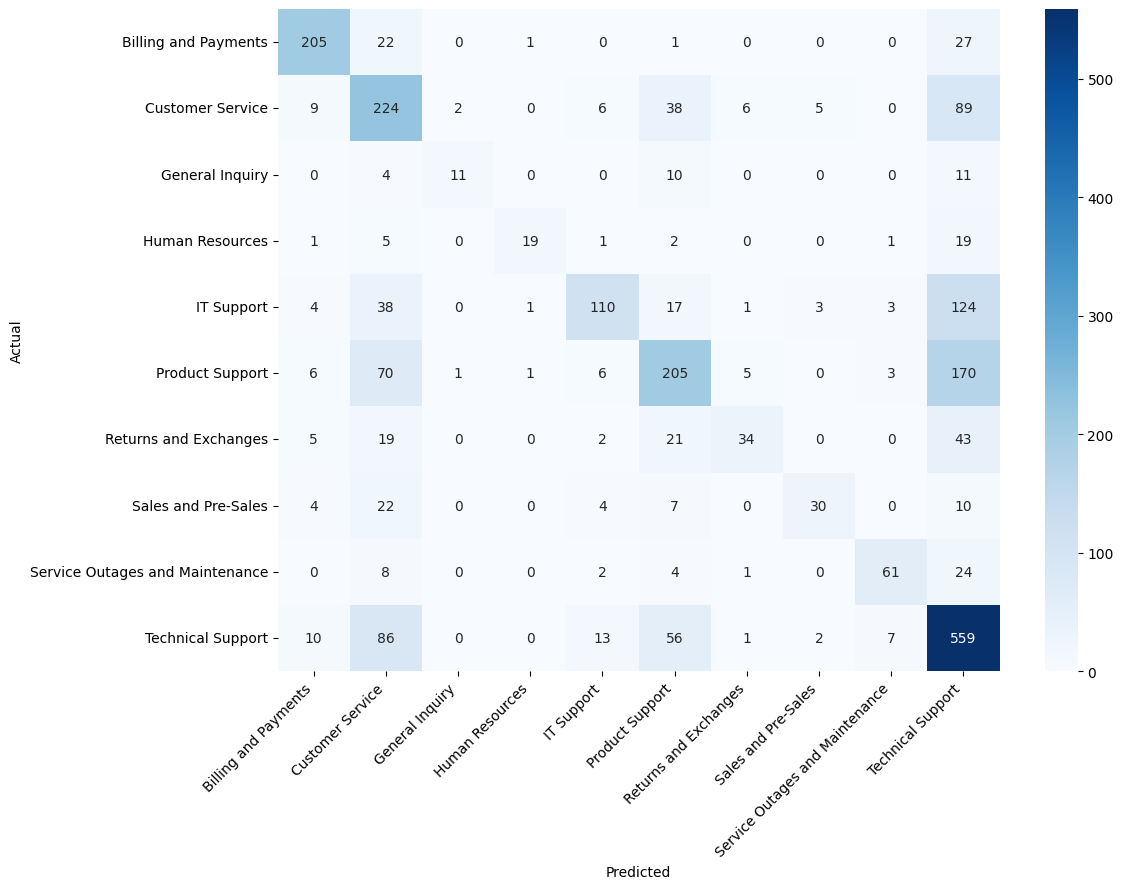

In [ ]:
# ══════════════════════════════════════════════════════════════
# Evaluation
# ══════════════════════════════════════════════════════════════

from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

val_pred  = final_rf.predict(X_val_w2v)
test_pred = final_rf.predict(X_test_w2v)

val_acc  = accuracy_score(y_val, val_pred)
test_acc = accuracy_score(y_test, test_pred)

val_f1_macro  = f1_score(y_val, val_pred, average="macro", zero_division=0)
test_f1_macro = f1_score(y_test, test_pred, average="macro", zero_division=0)

print("\n" + "=" * 60)
print("  FINAL RESULTS: Word2Vec + Random Forest")
print("=" * 60)
print(f"Validation Accuracy : {val_acc:.4f}")
print(f"Validation F1-macro : {val_f1_macro:.4f}")
print(f"Test Accuracy       : {test_acc:.4f}")
print(f"Test F1-macro       : {test_f1_macro:.4f}")

print("\nClassification Report - Test Set:\n")
print(classification_report(y_test, test_pred))

cm = confusion_matrix(y_test, test_pred)
labels = sorted(y_test.unique())

plt.figure(figsize=(12, 9))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)


plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("w2v_rf_confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()